<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/24_Poisoning_Attacks_Against_QML/QNN_PoisoningUnlearning_Chen2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# QNN versus MLP under data poisoning, and quantum machine unlearning: Chen & Zhang (2026) step by step

This notebook re-implements, runs and checks the numerical experiments of

> Yu-Qin Chen and Shi-Xin Zhang, "Superior resilience to poisoning and amenability to unlearning in quantum machine learning",
> *Nature Communications* (2026). https://doi.org/10.1038/s41467-026-70420-4 (preprint arXiv:2508.02422).
> Authors' code and released data: https://github.com/yutuer21/quantum-machine-unlearning (pinned here at commit `37f1856`), archived at Zenodo, doi 10.5281/zenodo.18641024.

**The story in five sentences.** Training data are often wrong: labels get flipped by annotation errors or by an attacker (*data poisoning*). The paper compares a small
classical neural network (an MLP) with a quantum neural network (QNN, a parameterised circuit that reads its input as the amplitudes of a quantum state) on two tasks,
recognising the digit 1 versus 9 in MNIST and recognising the two phases of a quantum spin chain from its ground state. It finds that the MLP's accuracy on clean test data
falls steadily as more training labels are flipped, whereas the QNN keeps a plateau and breaks down only near 50 % noise. It then asks how to *unlearn* the bad samples without
retraining from scratch (Finetune, Scrub, Gradient ascent versus Retrain) and finds that the QNN is much more amenable to cheap unlearning. Finally it blames the shape of the loss landscape
(measured by the trace of the Hessian) for the difference. This notebook redraws Figs. 2, 3a, 3b and 3d of the paper on a CPU simulator and gives a verdict for every claim.

**What the notebook does.**
1. Downloads MNIST (public) and the authors' released XXZ-chain ground states (public GitHub file); rebuilds the two classification tasks exactly as the authors' code does, and cross-checks the ground states with our own exact diagonalisation.
2. Builds the QNN with a fast exact simulator (a Heisenberg-picture trick specific to this circuit) and **proves** (to 1e-15) that it equals a full PennyLane state-vector simulation; draws the executed circuits.
3. Trains the MLP and the QNN under label flipping and feature randomization for a grid of noise ratios (Fig. 2), plus classical baselines on identical inputs.
4. Runs the four unlearning methods on models poisoned with 30 % flipped labels (Figs. 3a, 3b).
5. Measures the Landscape Roughening Ratio, the ratio of Hessian traces of the noisy to the clean model (Fig. 3d).
6. Compares every number with the authors' own released plot data and gives a verdict (reproduced / not reached / cannot be checked) per claim, then reads the paper critically.

**How to run.** Colab, CPU runtime, *Runtime -> Run all*. `FAST_MODE = True` (the committed, executed version) is a reduced protocol: 6 noise ratios, 2 seeds, 100 instead of 400 MLP epochs on the XXZ task and 25 unlearning steps; it takes about 10-12 minutes on an idle 4-core laptop CPU (about 25 minutes on the heavily shared machine on which it was validated). Set `FAST_MODE = False` in the configuration cell for the authors' full protocol
(10 noise ratios x 5 seeds, their epochs and learning rates, 50 unlearning steps; two to three hours on a shared CPU, not executed here). No GPU, no quantum hardware and no account are needed (all data are public; if you ever point the data cells at a gated Hugging Face dataset, put your own token in Colab *Secrets* under the name `HF_TOKEN` - the notebook reads it only from the environment or Colab Secrets).

**What you get at the end.** The paper's figures redrawn from your own runs next to the authors' released curves, a claim-by-claim verdict table, the circuit diagrams, and a critical reading of what these experiments can and cannot show.

## The paper in one page

**Problem.** How do classical and quantum neural networks respond to *training-time* data corruption, and can a corrupted model be repaired cheaply ("machine unlearning") instead of retrained?

**Two corruptions.** *Label flipping*: a fraction alpha of the training labels is inverted (0 <-> 1). *Feature randomization*: a fraction alpha of the input vectors is replaced by random noise (the label is kept).

**Two tasks (binary classification).** (i) MNIST digits '1' versus '9', 250 training images per digit, 1000 validation images. (ii) Ground states of the 12-spin XXZ chain, H = sum (sx sx + sy sy + Delta sz sz), classified as gapless (Delta <= 1) or gapped (Delta > 1); the 4096-dimensional wave function is the input.

**Two models.** *MLP*: ReLU network with two hidden layers and a sigmoid output (for the XXZ task the real and imaginary parts of the wave function are concatenated). *QNN*: the input vector is loaded as the amplitudes of a state (10 qubits for MNIST, 12 for XXZ), followed by `D` layers of RX-RY-RX rotations and a chain of RZZ gates (D = 6 for MNIST, 4 for XXZ); the output is a scaled sigmoid of the expectation value of Pauli-Z on the last qubit. The QNN has 234 trainable angles for MNIST, the MLP about 12 600 weights.

**Unlearning.** Starting from a model trained on D_train = D_retain + D_forget (the polluted samples), four procedures are compared, one *unlearning step* being one epoch: **Retrain** (new random model on D_retain only), **Finetune** (continue training the polluted model on D_retain), **Scrub** (retain loss plus a term that pushes the student away from the polluted teacher on D_forget) and **Gradient ascent** (retain loss minus beta times the loss on the polluted D_forget). Accuracy is measured on a clean validation set.

**Mechanism.** The Hessian trace of the loss at the trained parameters is computed for models trained on clean and on noisy data; the *Landscape Roughening Ratio* LRR = Tr H(noisy) / Tr H(clean) measures how much the landscape sharpens to memorise the noise.

**Claims to check.**
1. Label flipping: the MLP's validation accuracy decreases continuously and immediately; the QNN keeps a plateau and collapses at a critical ratio alpha_c ~ 0.5 (Fig. 2c MNIST, Fig. 2d XXZ).
2. Feature randomization: both models are robust on MNIST; on the small XXZ set the MLP degrades for alpha > 0.8 while the QNN stays unaffected (Fig. 2c, 2d).
3. Unlearning (alpha = 0.3): the MLP needs Retrain, cheaper methods lag behind ("stubborn memories"); for the QNN the approximate methods beat Retrain in the same time window (Figs. 3a, 3b).
4. The MLP's LRR is of order 10^2, the QNN's is about 1 (Fig. 3d).
5. Not reproducible here: the supplementary information (extra architectures, SVM / CNN / ResNet, forget-set accuracy, the analytic proofs) is not in the text we have; claims that rest on it are marked "cannot be checked".

### What follows the paper and what had to be chosen

The main text defers the optimiser settings to its supplement. The authors' public code (pinned commit above) fills most of the gaps; where it differs from the text we say so. `# CHOICE` marks our own decisions in the code.

| Item | Paper | This notebook |
|---|---|---|
| Circuit size | 10 qubits, depth 6 (MNIST); 12 qubits, depth 4 (XXZ) | same |
| RZZ topology | "linear chain" (234 angles for MNIST) | linear chain, 234 angles (`# CHOICE` follows the text). **The authors' code closes the chain into a ring (240 angles)**; this cannot be simulated with our fast exact method |
| Rotation order, RZZ sign | RX, RY, RX; exp(+i theta/2 ZZ) | RX, RY, RX; PennyLane `IsingZZ` = exp(-i theta/2 ZZ) (a sign of the trainable angle: no effect) |
| Output | "scaled sigmoid" of <Z_last> | sigmoid(5 <Z_last>) (authors' code) |
| Initialisation | not stated | QNN angles N(0, 0.01^2) (authors' code); MLP Glorot-uniform weights, zero biases (Keras default) |
| Optimiser | supplement | Adam. MNIST: QNN lr 0.005, MLP lr 0.005, 100 epochs, batch 256. XXZ: QNN lr 0.03, 200 epochs, batch 32; MLP lr 0.01, 400 epochs, batch 32 (authors' scripts; FAST mode uses 100 MLP epochs on XXZ) |
| MLP hidden layers | "two hidden layers"; 16 and 4 units in the Fig. 3 caption | 64-16 for Fig. 2 and the XXZ unlearning, 16-4 for MNIST unlearning and for the LRR (authors' scripts) |
| MLP input | "flattened pixels" | L2-normalised pixels (the same unit vector the QNN receives; authors' code); XXZ: real and imaginary parts (8192 numbers) |
| MNIST subset | 250 images per digit, 1000 validation images | the first 250 '1' and first 250 '9' of the Keras training split; first 1000 test images of the two digits (authors' code) |
| XXZ data | Delta in [-0.96, 0.96] and [1.02, 3.00] (step 0.02), validation at odd hundredths | the authors' released file: 82 training states (Delta = -0.80 ... 0.80 and 1.12 ... 2.72 in steps of 0.04) and 84 validation states, each with an **arbitrary global phase**; `XXZ_SOURCE = "ed"` regenerates the text's grids with our own exact diagonalisation (real states) |
| Label flipping | "a fraction alpha" | an even number int(alpha N) of flips, half from each class (authors' code) |
| Feature randomization | random vector | N(0, 0.1^2) per component (complex for XXZ), L2-normalised, label kept (authors' code); the text says N(0, 1) before normalisation, which is the same after normalisation |
| Noise grid, runs | not stated, 5 optimisation runs | alpha = 0.0 ... 0.9 (authors' released data), 5 seeds; FAST mode uses 6 values and 2 seeds |
| Unlearning set-up | forget set = polluted samples | alpha = 0.3 label flipping; the 30 % flipped samples are D_forget, the other 70 % D_retain; 50 steps (FAST: 25) |
| Scrub / Gradient ascent weights | lambda_ce, lambda_kl, lambda_fo "tuned"; beta | forget-term weight 0.2 for both, retain-KL weight 0 (authors' scripts); the Scrub term is the Keras `KLDivergence` p_t log(p_t / p_s) on the single sigmoid output, not the full Bernoulli KL of the paper's Eq. (8) |
| Unlearning learning rates | supplement | MNIST: MLP 0.001 (batch = whole retain set), QNN 0.005 (batch 256); XXZ: MLP 0.01, QNN 0.005 (batch = whole retain set); pre-training as in Experiment 1 except the MNIST MLP (16-4, lr 0.01, batch 128) |
| Polluted starting model | one pre-trained model, 5 unlearning runs | one independent polluted model per run (`# CHOICE`; the spread therefore includes the pre-training) |
| Hessian / LRR | "Hessian at the converged parameters", 5 initialisations | the authors' Hessian script: clean held-out loss on 100 images, 70/30 split of the 500 images, 50 epochs, batch 32, Adam 0.01; the trace is a **Hutchinson estimate** (50 Rademacher probes; exact eigenvalue sums are impossible for 12 600 parameters here), alpha = 0.1 ... 0.5 |
| Simulator | TensorCircuit-NG (JAX) | exact PyTorch simulator (Heisenberg picture, light cone), asserted equal to PennyLane; no sampling noise, no hardware |
| Hardware / noise | none | none |

## 0. Setup

In [1]:
# Pinned install: Colab already ships numpy, pandas, scikit-learn, matplotlib and torch; PennyLane (used to draw and to check the circuits) is the only extra.
import subprocess, sys
try:
    IN_COLAB = "google.colab" in sys.modules
except Exception:
    IN_COLAB = False
try:
    import pennylane  # noqa: F401
    NEED_INSTALL = IN_COLAB and pennylane.__version__ != "0.45.1"
except Exception:
    NEED_INSTALL = True
if NEED_INSTALL:
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "pennylane==0.45.1", "pylatexenc"], check=False)
    print("Installed pennylane==0.45.1 (if Colab asks, restart the runtime once and Run all again).")
else:
    print("PennyLane already available; nothing to install.")

PennyLane already available; nothing to install.


### Configuration

Every tunable constant is in the next cell. The committed notebook was executed with the `FAST_MODE` value printed in its first output line. `IBM_TOKEN` is unused: the paper has no hardware experiment.
Two things are worth knowing before reading the numbers. (1) Everything is a *noiseless* classical simulation of the circuit, exactly as in the paper. (2) The learning rates, epochs and batch sizes are those of the authors' public scripts, not of the paper text.

In [2]:
# ---------------------------------------------------------------------------------------------
# CONFIGURATION: every tunable constant lives in this cell.
# FAST_MODE = True : reduced protocol (6 noise ratios, 2 seeds instead of 5, 100 instead of 400 MLP epochs on XXZ, 25 unlearning steps): about 10-12 minutes on an idle
#                     4-core laptop, about 25 minutes on a heavily shared CPU. The committed notebook was executed in this mode.
# FAST_MODE = False: the authors' protocol (10 noise ratios x 5 seeds, their epochs / batch sizes / learning rates, 50 unlearning steps); measured at roughly 4x the FAST cost
#                     per experiment plus 4x for the XXZ MLP, i.e. 2-3 hours on a shared CPU (about 1 hour on an idle laptop). Not executed for the committed notebook.
# ---------------------------------------------------------------------------------------------
import os
FAST_MODE = True
SEED = 42                          # master seed (data corruption, initialisation, mini-batch order all derive from it)
DATA_DIR = os.environ.get("QPOISON_DATA_DIR", "qpoison_data")     # cache for MNIST and the authors' XXZ ground states (downloaded automatically)
IBM_TOKEN = ""                     # unused: the paper has no hardware experiment (all results are noiseless simulations)
N_THREADS = 2                      # torch threads (the circuit matrices are tiny; more threads do not help)

# --- data -------------------------------------------------------------------------------------
AUTHORS_REPO = "yutuer21/quantum-machine-unlearning"
AUTHORS_COMMIT = "37f1856526411e85fcabe939a119aa8c57134f32"       # pinned commit of the authors' public code and data
XXZ_SOURCE = "authors"             # "authors": ground states released by the authors (random global phases); "ed": our own exact diagonalisation (real states)
USE_AUTHORS_PLOT_DATA = True       # download the authors' released curves of Figs. 2c, 2d, 3a, 3b to compare with ours (allow-listed unpickling)

# --- Experiment 1: resilience to poisoning (Fig. 2) --------------------------------------------
ALPHAS = (0.0, 0.2, 0.4, 0.5, 0.6, 0.8) if FAST_MODE else (0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9)    # paper: 0.0 ... 0.9
N_SEEDS = 2 if FAST_MODE else 5                                   # paper: 5 optimisation runs
CHUNK = {"qnn": 10, "mlp": 25}     # models trained side by side (memory/time trade-off only, no effect on results)
# optimiser settings of the authors' code (Adam everywhere); the paper defers them to its supplement
TASK_CFG = {
    "mnist": {"qnn": dict(depth=6, epochs=100, bs=256, lr=0.005),
              "mlp": dict(hidden=(64, 16), epochs=100, bs=256, lr=0.005)},
    "xxz":   {"qnn": dict(depth=4, epochs=200, bs=32, lr=0.03),
              "mlp": dict(hidden=(64, 16), epochs=100 if FAST_MODE else 400, bs=32, lr=0.01)},     # authors: 400 epochs (FAST mode: 100)
}

# --- Experiment 2: unlearning (Fig. 3a, 3b) ----------------------------------------------------
UNL_ALPHA = 0.3                    # label-flipping ratio of the polluted training set (the flipped samples are the forget set)
UNL_SEEDS = 2 if FAST_MODE else 5  # paper: 5 runs
UNL_EPOCHS = 25 if FAST_MODE else 50                               # one unlearning step = one epoch; paper/authors: 50 steps
W_SCRUB, W_GA = 0.2, 0.2           # weight of the forget-set term in Scrub / Gradient ascent (authors' choice; the retain-set KL weight is 0)
UNL = {   # pre-training of the polluted model and unlearning settings of the authors' scripts (bs None = the whole retain set per step)
    "mnist": {"qnn": dict(pre=dict(depth=6, epochs=100, bs=256, lr=0.005), bs=256, lr=0.005),
              "mlp": dict(pre=dict(hidden=(16, 4), epochs=100, bs=128, lr=0.01), bs=None, lr=0.001)},
    "xxz":   {"qnn": dict(pre=dict(depth=4, epochs=200, bs=32, lr=0.03), bs=None, lr=0.005),
              "mlp": dict(pre=dict(hidden=(64, 16), epochs=100 if FAST_MODE else 400, bs=32, lr=0.01), bs=None, lr=0.01)},
}

# --- Experiment 3: loss-landscape curvature (Fig. 3d) ------------------------------------------
LRR_ALPHAS = (0.2, 0.4) if FAST_MODE else (0.1, 0.2, 0.3, 0.4, 0.5)
LRR_SEEDS = 2 if FAST_MODE else 5  # paper / authors' script: 5 seeds
LRR_PROBES = 20 if FAST_MODE else 50                              # Rademacher probes of the Hutchinson trace estimator
LRR_TRAIN = dict(epochs=50, bs=32, lr=0.01)                       # authors' Hessian script: 50 epochs, batch 32, Adam 0.01
LRR_HESS_SAMPLES = 100             # clean held-out samples on which the Hessian of the loss is evaluated (authors' script)
LRR_MLP_HIDDEN, LRR_QNN_DEPTH = (16, 4), 6                        # Fig. 3 caption: ReLU MLP 16-4 and a 10-qubit, 6-layer ansatz

print(dict(FAST_MODE=FAST_MODE, ALPHAS=ALPHAS, N_SEEDS=N_SEEDS, UNL_EPOCHS=UNL_EPOCHS, LRR_ALPHAS=LRR_ALPHAS))

{'FAST_MODE': True, 'ALPHAS': (0.0, 0.2, 0.4, 0.5, 0.6, 0.8), 'N_SEEDS': 2, 'UNL_EPOCHS': 25, 'LRR_ALPHAS': (0.2, 0.4)}


In [3]:
import io, time, json, copy, math, pickle, warnings, subprocess
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
import pennylane as qml
import sklearn
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
warnings.filterwarnings("ignore")
torch.set_default_dtype(torch.float64)
torch.set_num_threads(N_THREADS)
os.makedirs(DATA_DIR, exist_ok=True)
rng_master = np.random.default_rng(SEED)
np.random.seed(SEED); torch.manual_seed(SEED)
EPS_CLIP = 1e-7                    # Keras clips probabilities to [1e-7, 1 - 1e-7] inside binary cross-entropy; we do the same
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.25})
print("numpy", np.__version__, "| pandas", pd.__version__, "| sklearn", sklearn.__version__, "| matplotlib", matplotlib.__version__)
print("torch", torch.__version__, "| pennylane", qml.__version__)

numpy 2.5.4 | pandas 3.0.6 | sklearn 1.9.1 | matplotlib 3.11.2
torch 2.14.1+cpu | pennylane 0.45.1


## 1. A fast exact simulator for the QNN, an MLP, and the training / unlearning code

The authors simulate the QNN with TensorCircuit-NG on JAX. We use PyTorch and a trick that is **exact** (not an approximation) for this circuit: only Pauli-Z on the *last* qubit is measured, so
<Z_last> = <x| W^dagger Z_last W |x> where W is the whole circuit. Conjugating Z_last backwards through the layers (Heisenberg picture), the operator O = W^dagger Z_last W grows by one qubit per layer, so it acts on only the last `depth` qubits
(6 of 10 for MNIST, 4 of 12 for XXZ): a 64 x 64 (resp. 16 x 16) matrix. The data enter only through the reduced density matrix of those qubits, computed once. The cell below defines this simulator for an *ensemble* of R independent QNNs
(so that many noise ratios and seeds are trained side by side), an equally batched MLP, the Adam training loop, the two poisoning protocols, the four unlearning methods and the Hutchinson Hessian-trace estimator.
The circuit section further below asserts that the simulator equals PennyLane's full simulation to 1e-9 (in practice 1e-15).

In [4]:
# ------------------------------------------------------------------------------------------------
# QNN ensemble: R independent copies of the paper's circuit, trained side by side
# ------------------------------------------------------------------------------------------------
class QNNEnsemble(nn.Module):
    """R independent QNNs (own parameters, own data), exact simulation.
    Circuit per model: amplitude encoding -> D x [ RX RY RX on every qubit ; RZZ on neighbours (linear chain) ] -> <Z_last> -> sigmoid(scale * <Z>).
    Exact shortcut (not an approximation): only Z on the last wire is measured, so <Z_last>(x) = x^dagger (I (x) O) x where the Hermitian matrix O
    acts on the last k = min(D, n) wires. O is obtained by conjugating Z_last backwards through the circuit (Heisenberg picture), which also lets us
    skip the gates outside the light cone. The data enter only through the reduced density matrix rho of the last k wires, computed once per
    data set. The result equals PennyLane's full state-vector simulation to ~1e-16 (asserted in the circuit section)."""

    def __init__(self, R, n, depth, scale=5.0, init_std=0.01, seeds=None):
        super().__init__()
        self.R, self.n, self.depth, self.scale = R, n, depth, scale
        self.k = min(depth, n)
        self.P = depth * (3 * n + (n - 1))
        self.zz_by_size, self.z_by_size = {}, {}
        for s in range(1, self.k + 1):                       # eigenvalue tables of Z_j Z_{j+1} on the last s wires
            idx = np.arange(2 ** s)
            z = 1 - 2 * ((idx[:, None] >> (s - 1 - np.arange(s))[None, :]) & 1)
            self.zz_by_size[s] = torch.tensor(z[:, :-1] * z[:, 1:], dtype=torch.float64)
            self.z_by_size[s] = torch.tensor(z[:, -1], dtype=torch.float64)
        k = self.k
        self.iu, self.ju = np.triu_indices(2 ** k)
        self.fac = torch.tensor(np.where(self.iu == self.ju, 1.0, 2.0))
        seeds = list(range(R)) if seeds is None else list(seeds)
        th = torch.stack([torch.randn(self.P, generator=torch.Generator().manual_seed(int(s))) * init_std for s in seeds])
        self.theta = nn.Parameter(th)

    @staticmethod
    def _rx(a):
        c, s = torch.cos(a / 2), torch.sin(a / 2)
        z = torch.zeros_like(c)
        return torch.stack([torch.complex(c, z), torch.complex(z, -s), torch.complex(z, -s), torch.complex(c, z)], -1).reshape(*a.shape, 2, 2)

    @staticmethod
    def _ry(a):
        c, s = torch.cos(a / 2), torch.sin(a / 2)
        z = torch.zeros_like(c)
        return torch.stack([torch.complex(c, z), torch.complex(-s, z), torch.complex(s, z), torch.complex(c, z)], -1).reshape(*a.shape, 2, 2)

    def observable(self, theta=None):
        """O = W^dagger (I (x) Z_last) W on the last k wires, for all R models: (R, 2^k, 2^k) complex.
        Going backwards through the layers the operator grows by one wire per layer (RZZ couples it to its left neighbour)."""
        theta = self.theta if theta is None else theta
        n, k, L, R = self.n, self.k, self.depth, theta.shape[0]
        t = theta.reshape(R, L, 3 * n + (n - 1))
        rot, zz = t[:, :, :3 * n].reshape(R, L, n, 3), t[:, :, 3 * n:]
        O = torch.diag(self.z_by_size[1].to(torch.complex128)).expand(R, -1, -1)           # Z on the last wire: size 1
        cur = 1
        for l in range(L - 1, -1, -1):
            s = min(L - l, k)
            if l < L - 1:                                                                  # the RZZ layer after the last rotations commutes with Z_last
                if s > cur:                                                                # RZZ extends the support by one wire to the left
                    eye = torch.eye(2, dtype=torch.complex128)
                    O = torch.einsum("ab,rcd->racbd", eye, O).reshape(R, 2 ** s, 2 ** s)
                    cur = s
                ph = torch.exp(-0.5j * (zz[:, l, n - 1 - (s - 1):] @ self.zz_by_size[s].T))  # (R, 2^s): RZZ(t) = exp(-i t/2 Z Z) on the last s wires
                O = ph.conj()[:, :, None] * O * ph[:, None, :]                              # R^dagger O R (R diagonal)
            ang = rot[:, l, n - cur:]                                                      # rotations of the last `cur` wires
            U = self._rx(ang[..., 2]) @ self._ry(ang[..., 1]) @ self._rx(ang[..., 0])      # (R, cur, 2, 2): RX first, then RY, then RX
            M = U[:, 0]
            for q in range(1, cur):                                                        # Kronecker product over the wires
                M = torch.einsum("rab,rcd->racbd", M, U[:, q]).reshape(R, M.shape[-2] * 2, M.shape[-1] * 2)
            O = M.conj().transpose(-1, -2) @ O @ M
        return O

    def reduced(self, x, dtype=torch.float32):
        """Packed reduced density matrix of the last k wires for amplitude vectors x (B, 2^n): upper triangle (i <= j) of rho_ij = sum_a conj(x_ai) x_aj,
        shape (B, 2^k (2^k + 1) / 2). Real for real x (float32 by default to save memory), complex otherwise."""
        x = torch.as_tensor(x)
        xr = x.reshape(x.shape[0], 2 ** (self.n - self.k), 2 ** self.k)
        rho = torch.einsum("bai,baj->bij", xr.conj(), xr) if x.is_complex() else torch.einsum("bai,baj->bij", xr, xr)
        rho = rho[:, self.iu, self.ju]
        if rho.is_complex():
            return rho.to(torch.complex64 if dtype == torch.float32 else torch.complex128)
        return rho.to(dtype)

    def logits(self, rho, theta=None):
        """rho: packed (R, B, Dp) per-model data, or (B, Dp) shared by all models. Returns scale * <Z_last> of shape (R, B).
        <Z_last> = x^dagger O x = sum_{i<=j} rho_ij w_ij with w_ii = O_ii and w_ij = 2 O_ij (i<j); real part."""
        O = self.observable(theta)
        w = O[:, self.iu, self.ju] * self.fac
        if rho.is_complex():
            wr, wi = w.real.to(rho.real.dtype), w.imag.to(rho.real.dtype)
            if rho.dim() == 2:
                val = rho.real @ wr.T - rho.imag @ wi.T
                val = val.T
            else:
                val = torch.einsum("rbd,rd->rb", rho.real, wr) - torch.einsum("rbd,rd->rb", rho.imag, wi)
        else:
            wr = w.real.to(rho.dtype)
            val = (rho @ wr.T).T if rho.dim() == 2 else torch.einsum("rbd,rd->rb", rho, wr)
        return self.scale * val.to(torch.float64)

In [5]:
# ------------------------------------------------------------------------------------------------
# MLP ensemble (Keras-like: Dense-ReLU-Dense-ReLU-Dense-sigmoid, Glorot-uniform kernels, zero biases)
# ------------------------------------------------------------------------------------------------
class MLPEnsemble(nn.Module):
    def __init__(self, R, d_in, hidden=(16, 4), seeds=None, dtype=torch.float32):
        super().__init__()
        self.R, self.dtype = R, dtype
        sizes = [d_in, *hidden, 1]
        seeds = list(range(R)) if seeds is None else list(seeds)
        self.W, self.b = nn.ParameterList(), nn.ParameterList()
        for li, (a, b) in enumerate(zip(sizes[:-1], sizes[1:])):
            lim = math.sqrt(6.0 / (a + b))
            W = torch.stack([(torch.rand(a, b, generator=torch.Generator().manual_seed(int(s) * 101 + li)) * 2 - 1) * lim for s in seeds]).to(dtype)
            self.W.append(nn.Parameter(W)); self.b.append(nn.Parameter(torch.zeros(len(seeds), 1, b, dtype=dtype)))
        self.P = sum(a * b + b for a, b in zip(sizes[:-1], sizes[1:]))

    def logits(self, x):
        """x: (R, B, d) or (B, d) shared. Returns (R, B)."""
        h = x.to(self.dtype)
        if h.dim() == 2:
            h = h.unsqueeze(0).expand(self.W[0].shape[0], -1, -1)
        for li, (W, b) in enumerate(zip(self.W, self.b)):
            h = torch.baddbmm(b, h, W)
            if li < len(self.W) - 1:
                h = torch.relu(h)
        return h.squeeze(-1).to(torch.float64)


# ------------------------------------------------------------------------------------------------
# losses and training (all R models of an ensemble are independent: the loss is a sum of per-model means)
# ------------------------------------------------------------------------------------------------
def bce_from_logits(logit, y, eps=EPS_CLIP):
    """Keras-style binary cross-entropy: probabilities are clipped to [eps, 1-eps] (gradient 0 outside), shape (R, B) -> (R, B)."""
    p = torch.sigmoid(logit).clamp(eps, 1 - eps)
    return -(y * torch.log(p) + (1 - y) * torch.log(1 - p))


def accuracy(logit, y):
    return ((logit > 0).to(torch.float64) == y).to(torch.float64).mean(-1)      # (R,)


def make_optimizer(model, lr, kind):
    return torch.optim.Adam(model.parameters(), lr=lr, eps=1e-8 if kind == "qnn" else 1e-7)


def fit_ensemble(model, kind, X, Y, epochs, bs, lr, seed, eval_sets=None):
    """Mini-batch Adam with a fresh random permutation per epoch and per model. Y: (R, N); X: (R, N, D) per-model data or (N, D) shared.
    The QNN evaluates all N samples in one cheap product and then picks the batch; the MLP gathers the batch first."""
    R, N = Y.shape
    opt = make_optimizer(model, lr, kind)
    g = torch.Generator().manual_seed(int(seed))
    ar = torch.arange(R)[:, None]
    for ep in range(epochs):
        perm = torch.argsort(torch.rand(R, N, generator=g), dim=1)
        for i in range(0, N, bs):
            idx = perm[:, i:i + bs]
            if kind == "qnn":
                z = model.logits(X)[ar, idx]
            else:
                z = model.logits(X[idx] if X.dim() == 2 else X[ar, idx])
            loss = bce_from_logits(z, Y[ar, idx]).mean(1).sum()
            opt.zero_grad(); loss.backward(); opt.step()
    out = {}
    with torch.no_grad():
        out["train_acc"] = accuracy(model.logits(X), Y).numpy()
        for name, (Xe, Ye) in (eval_sets or {}).items():
            out[name] = accuracy(model.logits(Xe), Ye).numpy()
    return out

In [6]:
# ------------------------------------------------------------------------------------------------
# data poisoning (the authors' conventions: half of the corrupted samples are taken from each class)
# ------------------------------------------------------------------------------------------------
def balanced_indices(y, m, rng):
    """m sample indices, m/2 of each class."""
    return np.r_[rng.choice(np.where(y == 0)[0], m // 2, replace=False), rng.choice(np.where(y == 1)[0], m // 2, replace=False)]


def flip_labels(y, alpha, rng):
    """Label flipping y -> 1 - y for a fraction alpha of the samples (an even number, half per class). Returns (new labels, flipped indices)."""
    n_flip = int(len(y) * alpha); n_flip -= n_flip % 2
    idx = balanced_indices(y, n_flip, rng)
    y2 = y.copy(); y2[idx] = 1 - y2[idx]
    return y2, idx


def randomize_features(x, y, alpha, rng, sigma=0.1):
    """Feature randomization: a fraction alpha of the feature vectors is replaced by N(0, sigma^2) noise (complex for complex data), L2-normalised.
    The labels are left untouched. Returns (new features, replaced indices)."""
    n_poison = int(len(x) * alpha); n_poison += n_poison % 2
    idx = balanced_indices(y, n_poison, rng)
    x2 = x.copy()
    if len(idx):
        r = rng.normal(0, sigma, size=(len(idx), x.shape[1]))
        if np.iscomplexobj(x):
            r = r + 1j * rng.normal(0, sigma, size=(len(idx), x.shape[1]))
        x2[idx] = r / np.linalg.norm(r, axis=1, keepdims=True)
    return x2, idx

In [7]:
# ------------------------------------------------------------------------------------------------
# unlearning: Retrain / Finetune / Scrub / Gradient ascent, all (method, seed) pairs trained side by side
# ------------------------------------------------------------------------------------------------
METHODS = ("Retrain", "Finetune", "Scrub", "Grad-Asc")


def kl_term(p_teacher, p_student, eps=EPS_CLIP):
    """The authors' (Keras KLDivergence) term  mean( p_t * log(p_t / p_s) )  with probabilities clipped to [eps, 1]."""
    pt, ps = p_teacher.clamp(eps, 1.0), p_student.clamp(eps, 1.0)
    return (pt * torch.log(pt / ps)).mean(1)


def unlearn_ensemble(kind, fresh_model, teacher, data, epochs, bs, lr, w_scrub=0.2, w_ga=0.2, seed=0):
    """Run the four unlearning methods for every seed. Model r = method * S + seed (methods in the order of METHODS).
    data[s] : dict with Xr, yr (retain set), Xf, yf_clean, yf_pollu (forget set) for seed s; data['Xv'], data['yv'] : shared clean validation set.
    Returns the validation / forget-set / retain-set accuracy recorded at the start of every epoch: arrays of shape (4, S, epochs)
    (index 0 of the last axis is the polluted starting point; Retrain starts from a random initialisation)."""
    S = len(teacher.theta) if kind == "qnn" else teacher.W[0].shape[0]
    R = 4 * S
    m = fresh_model(R)                                           # random initialisation for every model (used as such by Retrain only)
    with torch.no_grad():                                        # Finetune / Scrub / Grad-Asc start from the polluted teacher of their seed
        for r in range(S, R):
            s = r % S
            if kind == "qnn":
                m.theta[r].copy_(teacher.theta[s])
            else:
                for pw, tw in zip(m.W, teacher.W): pw[r].copy_(tw[s])
                for pb, tb in zip(m.b, teacher.b): pb[r].copy_(tb[s])
    rs = [r % S for r in range(R)]
    Xr = torch.stack([data[s]["Xr"] for s in rs]); yr = torch.stack([data[s]["yr"] for s in rs])
    Xf = torch.stack([data[s]["Xf"] for s in rs]); yf_p = torch.stack([data[s]["yf_pollu"] for s in rs])
    yf_c = torch.stack([data[s]["yf_clean"] for s in rs])
    with torch.no_grad():                                        # teacher output on the forget set (clean features), fixed during unlearning
        pt = torch.sigmoid(teacher.logits(torch.stack([data[s]["Xf"] for s in range(S)])))[rs]
    c_sc = torch.tensor([w_scrub if r // S == 2 else 0.0 for r in range(R)])
    c_ga = torch.tensor([w_ga if r // S == 3 else 0.0 for r in range(R)])
    Xv, yv = data["Xv"], data["yv"]
    opt = make_optimizer(m, lr, kind)
    g = torch.Generator().manual_seed(int(seed))
    ar = torch.arange(R)[:, None]
    Nr = yr.shape[1]
    bs = Nr if bs is None else bs
    traj = {k: [] for k in ("val", "forget", "retain")}
    for ep in range(epochs):
        with torch.no_grad():
            traj["val"].append(accuracy(m.logits(Xv), yv).numpy())
            traj["forget"].append(accuracy(m.logits(Xf), yf_c).numpy())
            traj["retain"].append(accuracy(m.logits(Xr), yr).numpy())
        perm = torch.argsort(torch.rand(R, Nr, generator=g), dim=1)
        for i in range(0, Nr, bs):
            idx = perm[:, i:i + bs]
            zr = m.logits(Xr)[ar, idx] if kind == "qnn" else m.logits(Xr[ar, idx])
            loss = bce_from_logits(zr, yr[ar, idx]).mean(1)                    # cross-entropy on the retain batch (all methods)
            zf = m.logits(Xf)
            ce_f = bce_from_logits(zf, yf_p).mean(1)                           # cross-entropy on the polluted forget set (gradient ascent)
            kl_f = kl_term(pt, torch.sigmoid(zf))                               # teacher/student term on the forget set (Scrub)
            loss = loss - c_ga * ce_f - c_sc * kl_f
            opt.zero_grad(); loss.sum().backward(); opt.step()
    return {k: np.stack(v, -1).reshape(4, S, -1) for k, v in traj.items()}   # (4, S, epochs)

In [8]:
# ------------------------------------------------------------------------------------------------
# curvature: Hutchinson estimate of the Hessian trace (one number per model)
# ------------------------------------------------------------------------------------------------
def smooth_bce(logit, y):
    return y * F.softplus(-logit) + (1 - y) * F.softplus(logit)                # plain (unclipped) binary cross-entropy from logits


def hessian_trace(model, X, y, n_probe=50, seed=0):
    """Hutchinson estimator  Tr(H) ~ mean_v v^T H v  (Rademacher v) of the mean BCE on (X, y), for each of the R models of the ensemble."""
    params = [p for p in model.parameters()]
    g = torch.Generator().manual_seed(int(seed))
    loss = smooth_bce(model.logits(X), y).mean(1).sum()
    grads = torch.autograd.grad(loss, params, create_graph=True)
    est = torch.zeros(y.shape[0], dtype=torch.float64)
    for _ in range(n_probe):
        vs = [(torch.randint(0, 2, p.shape, generator=g).to(p.dtype) * 2 - 1) for p in params]
        gv = sum((gr * v).flatten(1).sum(1) for gr, v in zip(grads, vs))
        hv = torch.autograd.grad(gv.sum(), params, retain_graph=True)
        est += sum((h * v).flatten(1).sum(1) for h, v in zip(hv, vs)).to(torch.float64)
    return (est / n_probe).detach().numpy()

## 2. Data: MNIST 1 versus 9 and the XXZ chain

*MNIST* is downloaded from the Keras mirror (fallback: Hugging Face `ylecun/mnist`) and cached in `DATA_DIR`. The 500 training images are the first 250 '1' and the first 250 '9' of the Keras training split, the 1000 validation images are the first 1000 test images of the two digits; pixels are scaled to [0, 1] and each image is L2-normalised so that it is a valid quantum state.
*XXZ* ground states are the authors' released `1D_xxz_dataset.npz` (294 exact ground states of the 12-spin periodic chain for Delta from -3 to 2.98). We re-derive five of them with our own sparse exact diagonalisation (Lanczos in the Sz = 0 sector) and print the overlap, which is 1 up to the arbitrary global phase of the stored vectors.

In [9]:
MNIST_URLS = ["https://storage.googleapis.com/tensorflow/tf-keras-datasets/mnist.npz"]      # the same file Keras downloads (the authors use Keras)


def load_mnist(data_dir=DATA_DIR):
    """Download MNIST (cached). Primary: Keras mirror .npz; fallback: Hugging Face parquet (ylecun/mnist, public)."""
    cache = os.path.join(data_dir, "mnist.npz")
    if not os.path.exists(cache):
        import requests
        ok = False
        for url in MNIST_URLS:
            try:
                r = requests.get(url, timeout=120); r.raise_for_status()
                open(cache, "wb").write(r.content); ok = True; break
            except Exception as e:
                print("download failed:", url, e)
        if not ok:   # fallback: Hugging Face (token only used if present; MNIST itself is public)
            from huggingface_hub import hf_hub_download
            HF_TOKEN = os.environ.get("HF_TOKEN")
            if HF_TOKEN is None:
                try:
                    from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
                    HF_TOKEN = userdata.get("HF_TOKEN")
                except Exception:
                    HF_TOKEN = None
            from PIL import Image
            arrs = {}
            for split in ["train", "test"]:
                f = hf_hub_download("ylecun/mnist", f"mnist/{split}-00000-of-00001.parquet", repo_type="dataset", cache_dir=data_dir, token=HF_TOKEN)
                df = pd.read_parquet(f)
                arrs[f"x_{split}"] = np.stack([np.array(Image.open(io.BytesIO(d["bytes"]))) for d in df["image"]])
                arrs[f"y_{split}"] = df["label"].values.astype(np.uint8)
            np.savez_compressed(cache, **arrs)
    d = np.load(cache)
    return d["x_train"], d["y_train"], d["x_test"], d["y_test"]


MN_X, MN_Y, MN_XT, MN_YT = load_mnist()
print("MNIST train / test:", MN_X.shape, MN_XT.shape, "| digits", np.unique(MN_Y))

MNIST train / test: (60000, 28, 28) (10000, 28, 28) | digits [0 1 2 3 4 5 6 7 8 9]


In [10]:
def xxz_ground_state(L, delta):
    """Exact ground state of H = sum_i (sx_i sx_{i+1} + sy_i sy_{i+1} + delta sz_i sz_{i+1}) (Pauli matrices, periodic chain of L spins), found in the
    Sz = 0 sector (the ground state of an even chain lies there) with Lanczos. Real vector of length 2^L; global sign fixed so that the Neel amplitude
    is positive (`# CHOICE`: the paper does not say how the arbitrary phase of an eigenvector is fixed)."""
    import scipy.sparse as sp, scipy.sparse.linalg as spla
    N = 2 ** L
    states = np.arange(N)
    bits = (states[:, None] >> np.arange(L)[None, :]) & 1
    sec = states[bits.sum(1) == L // 2]
    pos = -np.ones(N, dtype=np.int64); pos[sec] = np.arange(len(sec))
    m = len(sec)
    diag = np.zeros(m); rows, cols = [], []
    for i in range(L):
        j = (i + 1) % L
        bi, bj = (sec >> i) & 1, (sec >> j) & 1
        diag += delta * np.where(bi == bj, 1.0, -1.0)                                  # delta * sz sz
        anti = np.where(bi != bj)[0]
        rows.append(pos[sec[anti] ^ ((1 << i) | (1 << j))]); cols.append(anti)         # sx sx + sy sy = 2 (s+ s- + s- s+)
    rows, cols = np.concatenate(rows), np.concatenate(cols)
    H = sp.csr_matrix((2.0 * np.ones(len(rows)), (rows, cols)), shape=(m, m)) + sp.diags(diag)
    w, v = spla.eigsh(H, k=1, which="SA", v0=np.ones(m) / np.sqrt(m), tol=1e-12)
    psi = np.zeros(N); psi[sec] = v[:, 0] / np.linalg.norm(v[:, 0])
    neel = sum(1 << i for i in range(1, L, 2))
    return (-psi if psi[neel] < 0 else psi), float(w[0])


def load_xxz_authors():
    """The authors' file 1D_xxz_dataset.npz (294 ground states of the 12-spin chain, xs complex (294, 4096), ys = Delta), pinned commit."""
    cache = os.path.join(DATA_DIR, "1D_xxz_dataset.npz")
    if not os.path.exists(cache):
        import requests
        url = f"https://raw.githubusercontent.com/{AUTHORS_REPO}/{AUTHORS_COMMIT}/src/1D_xxz_dataset.npz"
        r = requests.get(url, timeout=300); r.raise_for_status()
        open(cache, "wb").write(r.content)
    d = np.load(cache, allow_pickle=False)
    return d["xs"], d["ys"]


def build_xxz(source):
    """Returns (x_train, y_train, delta_train, x_val, y_val, delta_val); class 0 = gapless (Delta <= 1), class 1 = gapped (Delta > 1)."""
    if source == "authors":
        xs, ys = load_xxz_authors()
        # the authors' slices (datar.py, xxz_data): training = every other state, validation = the interleaved states in between
        tr = np.r_[np.arange(107, 189, 2), np.arange(200, len(ys) - 12, 2)]
        va = np.r_[np.arange(106, 190, 2), np.arange(199, len(ys) - 11, 2)]
        x_tr, d_tr, x_va, d_va = xs[tr], ys[tr], xs[va], ys[va]
    else:                                                           # the Delta lists printed in the paper's Methods
        d_tr = np.r_[np.round(np.arange(-0.96, 0.9601, 0.02), 2), np.round(np.arange(1.02, 3.0001, 0.02), 2)]
        d_va = np.round(np.arange(-0.97, 2.9901, 0.02), 2)
        x_tr = np.stack([xxz_ground_state(12, d)[0] for d in d_tr]).astype(complex)
        x_va = np.stack([xxz_ground_state(12, d)[0] for d in d_va]).astype(complex)
    return x_tr, (d_tr > 1.0).astype(int), d_tr, x_va, (d_va > 1.0).astype(int), d_va


try:
    XXZ_USED = XXZ_SOURCE
    XXZ_TR, XXZ_YTR, XXZ_DTR, XXZ_VA, XXZ_YVA, XXZ_DVA = build_xxz(XXZ_SOURCE)
except Exception as e:                                              # offline: fall back to our own exact diagonalisation
    print("authors' XXZ file unavailable (", type(e).__name__, "); using exact diagonalisation instead")
    XXZ_USED = "ed"
    XXZ_TR, XXZ_YTR, XXZ_DTR, XXZ_VA, XXZ_YVA, XXZ_DVA = build_xxz("ed")
print(f"XXZ ({XXZ_USED}): train {XXZ_TR.shape}, validation {XXZ_VA.shape}, class sizes train {np.bincount(XXZ_YTR)}, val {np.bincount(XXZ_YVA)}")

# sanity check of the data: our exact diagonalisation reproduces the stored states up to a global phase
chk = [XXZ_DTR[0], XXZ_DTR[len(XXZ_DTR) // 4], XXZ_DTR[len(XXZ_DTR) // 2 - 1], XXZ_DTR[len(XXZ_DTR) // 2], XXZ_DTR[-1]]
for d_ in chk:
    i_ = int(np.argmin(np.abs(XXZ_DTR - d_)))
    psi_ed, e0 = xxz_ground_state(12, float(XXZ_DTR[i_]))
    print(f"  Delta = {XXZ_DTR[i_]:+.2f}: |<psi_ED | psi_stored>| = {abs(np.vdot(psi_ed, XXZ_TR[i_])):.12f}   (E0 = {e0:.6f})")

XXZ (authors): train (82, 4096), validation (84, 4096), class sizes train [41 41], val [42 42]


  Delta = -0.80: |<psi_ED | psi_stored>| = 1.000000000000   (E0 = -12.369472)
  Delta = +0.00: |<psi_ED | psi_stored>| = 1.000000000000   (E0 = -15.454813)
  Delta = +0.80: |<psi_ED | psi_stored>| = 1.000000000000   (E0 = -20.156563)
  Delta = +1.12: |<psi_ED | psi_stored>| = 1.000000000000   (E0 = -22.427413)
  Delta = +2.72: |<psi_ED | psi_stored>| = 1.000000000000   (E0 = -36.997973)


In [11]:
# A "task" bundles one data set with everything the two models need: natural features, label arrays and the maps to the QNN / MLP inputs.
def l2(x):
    return x / (np.linalg.norm(x, axis=1, keepdims=True) + 1e-12)


# --- MNIST 1 vs 9: first 250 '1' and first 250 '9' of the Keras training split; validation = first 1000 test images of the two digits (authors' datar.py)
mn_tr = np.concatenate([MN_X[MN_Y == 1][:250], MN_X[MN_Y == 9][:250]]).reshape(500, -1) / 255.0
mn_va_mask = (MN_YT == 1) | (MN_YT == 9)
mn_va = MN_XT[mn_va_mask][:1000].reshape(1000, -1) / 255.0
TASKS = {
    "mnist": dict(
        name="mnist", n=10, x=l2(mn_tr), y=np.r_[np.zeros(250, int), np.ones(250, int)],
        xv=l2(mn_va), yv=(MN_YT[mn_va_mask][:1000] == 9).astype(int),
        amp=lambda x: torch.tensor(np.pad(x, ((0, 0), (0, 1024 - x.shape[1])))),                 # 784 pixels zero-padded to 1024 = 2^10 amplitudes
        vec=lambda x: torch.tensor(x.astype(np.float32)),                                         # the MLP sees the 784 normalised pixels
        rho_dtype=torch.float32, mlp_dtype=torch.float32, cfg=TASK_CFG["mnist"]),
    "xxz": dict(
        name="xxz", n=12, x=XXZ_TR, y=XXZ_YTR, xv=XXZ_VA, yv=XXZ_YVA,
        amp=lambda x: torch.tensor(x),                                                            # the 4096 complex amplitudes of the ground state
        vec=lambda x: torch.tensor(np.concatenate([x.real, x.imag], 1).astype(np.float32)),       # the MLP sees real and imaginary parts (8192 numbers)
        rho_dtype=torch.float64, mlp_dtype=torch.float32, cfg=TASK_CFG["xxz"]),
}
for t in TASKS.values():
    t["yv_t"] = torch.tensor(t["yv"], dtype=torch.float64)
    t["y_t"] = torch.tensor(t["y"], dtype=torch.float64)
    print(f"{t['name']:5s}: {len(t['y'])} training samples ({np.bincount(t['y'])} per class), {len(t['yv'])} validation samples ({np.bincount(t['yv'])}), "
          f"natural feature dimension {t['x'].shape[1]}, {t['n']} qubits")

mnist: 500 training samples ([250 250] per class), 1000 validation samples ([525 475]), natural feature dimension 784, 10 qubits
xxz  : 82 training samples ([41 41] per class), 84 validation samples ([42 42]), natural feature dimension 4096, 12 qubits


## Dataset Exploration and Visualisation

Everything below is computed from the real data (no synthetic data): shapes, feature names, the original label values and class counts, the real class distributions, example images, and two-dimensional scatter plots of the real observations coloured by their ground-truth label.
The models use *amplitude* encoding, not rotation angles, so the usual "[0, pi]-scaled angle" plot does not apply; instead we show the raw PCA coordinates (fitted on the training split only) and, for MNIST, the paper's own Fig. 1b: a t-SNE of the 500 real training images under the two corruption protocols.
For the XXZ states the plot also shows what the arbitrary global phase of the stored eigenvectors does to the raw (Re, Im) features.

In [12]:
mn, xz = TASKS["mnist"], TASKS["xxz"]
print("=== MNIST, digit '1' versus digit '9' ===")
print("raw MNIST             :", MN_X.shape, "training images of 28 x 28 pixels (uint8, 0..255);", MN_XT.shape[0], "test images")
print("used for training     :", mn["x"].shape, "= first 250 '1' + first 250 '9' of the Keras training split")
print("used for validation   :", mn["xv"].shape, "= first 1000 test images of the two digits")
print("features              : 784 pixel intensities  pixel_0 ... pixel_783, scaled to [0, 1] and L2-normalised (a unit vector, i.e. a quantum state)")
print("QNN input             : the same unit vector zero-padded to 1024 = 2^10 amplitudes -> 10 qubits (amplitude encoding)")
print("original label values :", sorted(np.unique(np.r_[MN_Y[MN_Y == 1], MN_Y[MN_Y == 9]]).tolist()), "-> binary label '1' = 0, '9' = 1")
print(pd.DataFrame({"train": np.bincount(mn["y"]), "validation": np.bincount(mn["yv"])}, index=["digit 1 (label 0)", "digit 9 (label 1)"]).T.to_string())
print()
print(f"=== XXZ chain ground states (L = 12 spins, source: {XXZ_USED}) ===")
print("training states       :", xz["x"].shape, "complex amplitudes <s|psi0(Delta)> of the exact ground state (4096 = 2^12 spin configurations s)")
print("validation states     :", xz["xv"].shape)
print("features              : 4096 complex amplitudes; the MLP receives their real and imaginary parts (8192 numbers); the QNN amplitude-encodes them on 12 qubits")
print("original label values : 0 = gapless phase (Delta <= 1), 1 = gapped antiferromagnetic phase (Delta > 1)")
print("Delta of training set : gapless", np.round(XXZ_DTR[XXZ_YTR == 0][[0, -1]], 2), f"({(XXZ_YTR == 0).sum()} states);  gapped", np.round(XXZ_DTR[XXZ_YTR == 1][[0, -1]], 2), f"({(XXZ_YTR == 1).sum()} states)")
print("Delta of validation   : gapless", np.round(XXZ_DVA[XXZ_YVA == 0][[0, -1]], 2), f"({(XXZ_YVA == 0).sum()} states);  gapped", np.round(XXZ_DVA[XXZ_YVA == 1][[0, -1]], 2), f"({(XXZ_YVA == 1).sum()} states)")
print(pd.DataFrame({"train": np.bincount(xz["y"]), "validation": np.bincount(xz["yv"])}, index=["gapless (label 0)", "gapped (label 1)"]).T.to_string())
imag_share = np.mean(np.sum(xz["x"].imag ** 2, 1))
print(f"mean share of the squared norm carried by the imaginary parts: {imag_share:.3f}  (0 would mean real eigenvectors; a random global phase gives about 0.5)")

=== MNIST, digit '1' versus digit '9' ===
raw MNIST             : (60000, 28, 28) training images of 28 x 28 pixels (uint8, 0..255); 10000 test images
used for training     : (500, 784) = first 250 '1' + first 250 '9' of the Keras training split
used for validation   : (1000, 784) = first 1000 test images of the two digits
features              : 784 pixel intensities  pixel_0 ... pixel_783, scaled to [0, 1] and L2-normalised (a unit vector, i.e. a quantum state)
QNN input             : the same unit vector zero-padded to 1024 = 2^10 amplitudes -> 10 qubits (amplitude encoding)
original label values : [1, 9] -> binary label '1' = 0, '9' = 1
            digit 1 (label 0)  digit 9 (label 1)
train                     250                250
validation                525                475

=== XXZ chain ground states (L = 12 spins, source: authors) ===
training states       : (82, 4096) complex amplitudes <s|psi0(Delta)> of the exact ground state (4096 = 2^12 spin configurations s)
validat

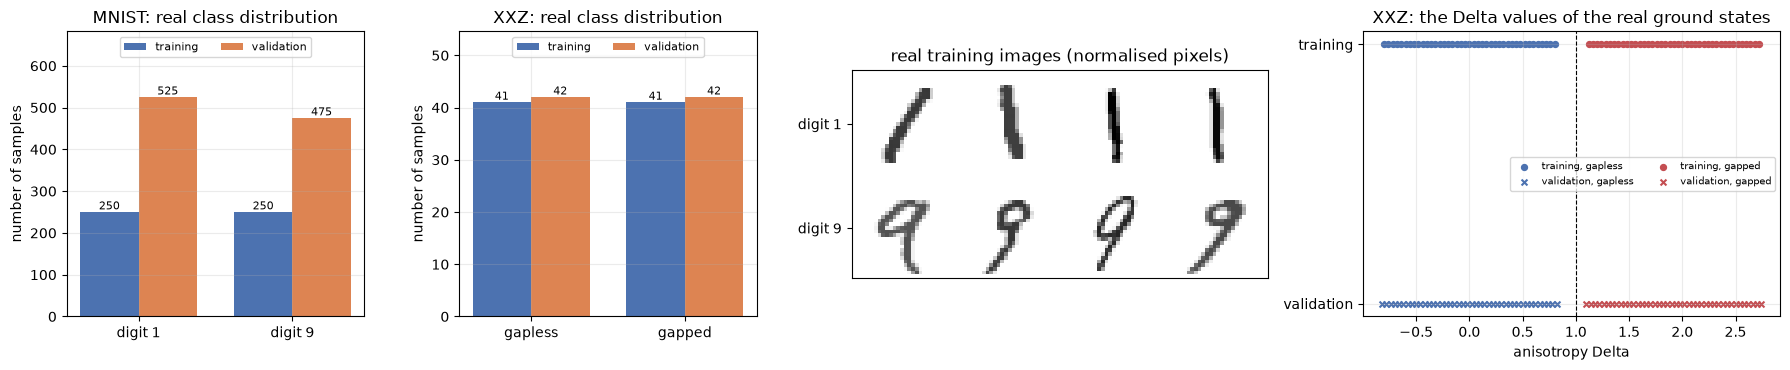

In [13]:
fig, ax = plt.subplots(1, 4, figsize=(18, 3.8), gridspec_kw=dict(width_ratios=[1, 1, 1.4, 1.4]))
w = 0.38
for a_, t_, names, ttl in [(ax[0], mn, ["digit 1", "digit 9"], "MNIST: real class distribution"), (ax[1], xz, ["gapless", "gapped"], "XXZ: real class distribution")]:
    a_.bar(np.arange(2) - w / 2, np.bincount(t_["y"]), w, label="training", color="#4C72B0")
    a_.bar(np.arange(2) + w / 2, np.bincount(t_["yv"]), w, label="validation", color="#DD8452")
    for i_, (c_tr, c_va) in enumerate(zip(np.bincount(t_["y"]), np.bincount(t_["yv"]))):
        a_.text(i_ - w / 2, c_tr, str(c_tr), ha="center", va="bottom", fontsize=8); a_.text(i_ + w / 2, c_va, str(c_va), ha="center", va="bottom", fontsize=8)
    a_.set_xticks([0, 1]); a_.set_xticklabels(names); a_.set_ylabel("number of samples"); a_.set_title(ttl); a_.set_ylim(0, 1.3 * max(np.bincount(t_["yv"]).max(), np.bincount(t_["y"]).max())); a_.legend(fontsize=8, loc="upper center", ncol=2)
grid_img = np.zeros((2 * 28, 4 * 28))
for c_ in range(2):
    for k_, i_ in enumerate(np.where(mn["y"] == c_)[0][:4]):
        grid_img[c_ * 28:(c_ + 1) * 28, k_ * 28:(k_ + 1) * 28] = mn["x"][i_].reshape(28, 28)
ax[2].imshow(grid_img, cmap="gray_r"); ax[2].set_xticks([]); ax[2].set_yticks([14, 42]); ax[2].set_yticklabels(["digit 1", "digit 9"])
ax[2].set_title("real training images (normalised pixels)"); ax[2].grid(False)
for cls_, col_, nm_ in [(0, "#4C72B0", "gapless"), (1, "#C44E52", "gapped")]:
    ax[3].scatter(XXZ_DTR[XXZ_YTR == cls_], np.ones((XXZ_YTR == cls_).sum()), s=18, color=col_, label=f"training, {nm_}")
    ax[3].scatter(XXZ_DVA[XXZ_YVA == cls_], np.zeros((XXZ_YVA == cls_).sum()), s=18, color=col_, marker="x", label=f"validation, {nm_}")
ax[3].axvline(1.0, color="k", ls="--", lw=0.8); ax[3].set_yticks([0, 1]); ax[3].set_yticklabels(["validation", "training"]); ax[3].set_xlabel("anisotropy Delta")
ax[3].set_title("XXZ: the Delta values of the real ground states"); ax[3].legend(fontsize=7, ncol=2, loc="center right")
plt.tight_layout(); plt.show()

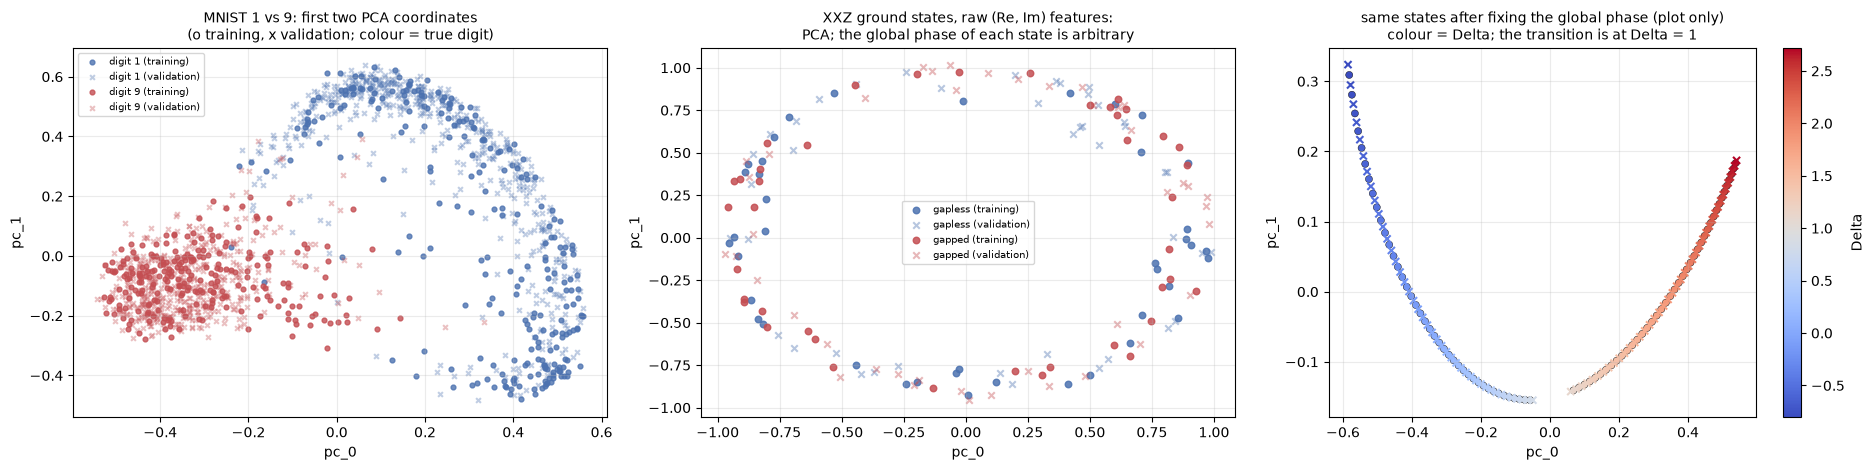

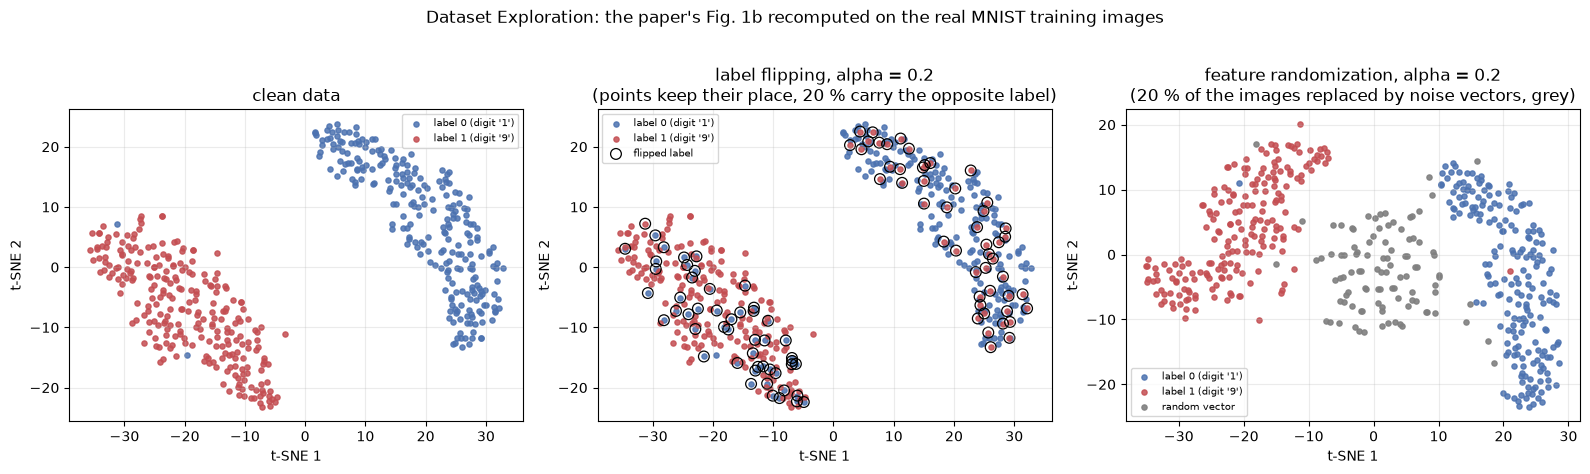

In [14]:
# Raw PCA coordinates (PCA fitted on the training split only). The models use AMPLITUDE encoding, not rotation angles, so the "[0, pi] angle" version of
# this plot does not apply; instead the second MNIST row reproduces the paper's Fig. 1b (t-SNE of the 500 training images, clean / label flipping / feature randomization).
fig, ax = plt.subplots(1, 3, figsize=(19, 4.8))
pm = PCA(n_components=2, random_state=SEED).fit(mn["x"])
Ptr, Pva = pm.transform(mn["x"]), pm.transform(mn["xv"])
for cls_, col_, nm_ in [(0, "#4C72B0", "digit 1"), (1, "#C44E52", "digit 9")]:
    ax[0].scatter(Ptr[mn["y"] == cls_, 0], Ptr[mn["y"] == cls_, 1], s=12, color=col_, alpha=0.8, label=f"{nm_} (training)")
    ax[0].scatter(Pva[mn["yv"] == cls_, 0], Pva[mn["yv"] == cls_, 1], s=12, color=col_, alpha=0.35, marker="x", label=f"{nm_} (validation)")
ax[0].set_title("MNIST 1 vs 9: first two PCA coordinates\n(o training, x validation; colour = true digit)", fontsize=10); ax[0].set_xlabel("pc_0"); ax[0].set_ylabel("pc_1"); ax[0].legend(fontsize=7)
def xyz_flat(x):
    return np.concatenate([x.real, x.imag], 1)
px = PCA(n_components=2, random_state=SEED).fit(xyz_flat(xz["x"]))
Qtr, Qva = px.transform(xyz_flat(xz["x"])), px.transform(xyz_flat(xz["xv"]))
for cls_, col_, nm_ in [(0, "#4C72B0", "gapless"), (1, "#C44E52", "gapped")]:
    ax[1].scatter(Qtr[xz["y"] == cls_, 0], Qtr[xz["y"] == cls_, 1], s=22, color=col_, alpha=0.85, label=f"{nm_} (training)")
    ax[1].scatter(Qva[xz["yv"] == cls_, 0], Qva[xz["yv"] == cls_, 1], s=22, color=col_, alpha=0.4, marker="x", label=f"{nm_} (validation)")
ax[1].set_title("XXZ ground states, raw (Re, Im) features:\nPCA; the global phase of each state is arbitrary", fontsize=10); ax[1].set_xlabel("pc_0"); ax[1].set_ylabel("pc_1"); ax[1].legend(fontsize=7)
def gauge_fix(x):                                                   # visualisation only: rotate every state so that its largest amplitude is real and positive
    ref = x[np.arange(len(x)), np.argmax(np.abs(x), 1)]
    return x * (np.conj(ref) / np.abs(ref))[:, None]
pg = PCA(n_components=2, random_state=SEED).fit(xyz_flat(gauge_fix(xz["x"])))
Gtr, Gva = pg.transform(xyz_flat(gauge_fix(xz["x"]))), pg.transform(xyz_flat(gauge_fix(xz["xv"])))
sc = ax[2].scatter(Gtr[:, 0], Gtr[:, 1], s=26, c=XXZ_DTR, cmap="coolwarm", edgecolor="k", linewidth=0.3)
ax[2].scatter(Gva[:, 0], Gva[:, 1], s=26, c=XXZ_DVA, cmap="coolwarm", marker="x")
plt.colorbar(sc, ax=ax[2], label="Delta"); ax[2].set_title("same states after fixing the global phase (plot only)\ncolour = Delta; the transition is at Delta = 1", fontsize=10); ax[2].set_xlabel("pc_0"); ax[2].set_ylabel("pc_1")
plt.tight_layout(); plt.show()

# Fig. 1b analogue: t-SNE of the 500 real training images with the paper's two corruption protocols (alpha = 0.2)
rng_v = np.random.default_rng(SEED)
y_flip_v, flip_idx_v = flip_labels(mn["y"], 0.2, rng_v)
x_rand_v, rand_idx_v = randomize_features(mn["x"], mn["y"], 0.2, rng_v)
fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))
emb_clean = TSNE(n_components=2, perplexity=30, init="pca", random_state=SEED, n_jobs=1).fit_transform(mn["x"])
emb_rand = TSNE(n_components=2, perplexity=30, init="pca", random_state=SEED, n_jobs=1).fit_transform(x_rand_v)
for a_, emb, yy, ttl in [(ax[0], emb_clean, mn["y"], "clean data"), (ax[1], emb_clean, y_flip_v, "label flipping, alpha = 0.2\n(points keep their place, 20 % carry the opposite label)"),
                        (ax[2], emb_rand, mn["y"], "feature randomization, alpha = 0.2\n(20 % of the images replaced by noise vectors, grey)")]:
    for cls_, col_, nm_ in [(0, "#4C72B0", "digit '1'"), (1, "#C44E52", "digit '9'")]:
        m_ = (yy == cls_) & (~np.isin(np.arange(500), rand_idx_v) if a_ is ax[2] else True)
        a_.scatter(emb[m_, 0], emb[m_, 1], s=14, color=col_, alpha=0.85, label=f"label {cls_} ({nm_})")
    if a_ is ax[1]:
        a_.scatter(emb[flip_idx_v, 0], emb[flip_idx_v, 1], s=60, facecolor="none", edgecolor="k", linewidth=0.9, label="flipped label")
    if a_ is ax[2]:
        a_.scatter(emb[rand_idx_v, 0], emb[rand_idx_v, 1], s=14, color="grey", alpha=0.9, label="random vector")
    a_.set_title(ttl); a_.set_xlabel("t-SNE 1"); a_.set_ylabel("t-SNE 2"); a_.legend(fontsize=7)
plt.suptitle("Dataset Exploration: the paper's Fig. 1b recomputed on the real MNIST training images", y=1.02)
plt.tight_layout(); plt.show()

## Quantum Circuit Architecture

The paper uses **one circuit family** for both tasks and draws it in its Fig. 4a: an N-qubit register initialised with the data as an *amplitude-encoded* state, `D` repeated layers, each layer being single-qubit rotations `RX, RY, RX` on every qubit followed by `RZZ` gates on neighbouring qubits (linear chain), and the expectation value of Pauli-Z on the **last** qubit, pushed through a scaled sigmoid. Only the size differs: **10 qubits, depth 6** for MNIST (1024 amplitudes = 784 pixels + 240 zeros) and **12 qubits, depth 4** for the XXZ ground states (4096 amplitudes). The two circuits are therefore drawn separately below with the real PennyLane circuit, which the first cell of this section proves equal (to 1e-9, in practice 1e-15) to the simulator used for training.

Things the paper does not say, and what this notebook assumes (`# CHOICE`): the order of the three rotations is RX, then RY, then RX (as drawn); the `RZZ` angle convention is PennyLane's `IsingZZ` (a sign flip of the trainable angle changes nothing); the sigmoid scale is 5 and the initial angles are N(0, 0.01^2) (both taken from the authors' code); the amplitude encoding is PennyLane's `AmplitudeEmbedding`, shown as one box. **Deviation of the authors' code from the paper's text:** the code closes the RZZ chain into a ring (an extra gate between the last and the first qubit, 240 instead of 234 angles for MNIST); this notebook follows the paper's text (linear chain, 234 angles, which is the number the paper quotes).

In [15]:
def make_qnode(n, depth):
    """The paper's QNN as a PennyLane circuit: amplitude encoding, `depth` x [RX RY RX on every qubit + RZZ on neighbouring qubits (linear chain)], <Z> of the last qubit."""
    dev = qml.device("default.qubit", wires=n)

    @qml.qnode(dev, interface="torch", diff_method="backprop")
    def circuit(x, theta):
        qml.AmplitudeEmbedding(x, wires=range(n), normalize=True)
        th = theta.reshape(depth, 3 * n + (n - 1))
        for l in range(depth):
            for q in range(n):
                qml.RX(th[l, 3 * q + 0], wires=q); qml.RY(th[l, 3 * q + 1], wires=q); qml.RX(th[l, 3 * q + 2], wires=q)
            for q in range(n - 1):
                qml.IsingZZ(th[l, 3 * n + q], wires=[q, q + 1])      # exp(-i theta/2 Z Z); the paper writes exp(+i theta/2 Z Z): a sign of the trainable angle
        return qml.expval(qml.PauliZ(n - 1))
    return circuit


ARCH = {"mnist": dict(n=10, depth=TASK_CFG["mnist"]["qnn"]["depth"]), "xxz": dict(n=12, depth=TASK_CFG["xxz"]["qnn"]["depth"])}
QNODES = {k: make_qnode(v["n"], v["depth"]) for k, v in ARCH.items()}
rows = []
for k, v in ARCH.items():
    ens = QNNEnsemble(2, v["n"], v["depth"], init_std=1.0, seeds=[1, 2])                  # generic angles of order 1 rad, two different circuits
    t = TASKS[k]
    amp = t["amp"](t["x"][:3])
    a = (ens.logits(ens.reduced(amp, dtype=torch.float64)) / ens.scale).detach()           # (2 models, 3 samples), fast simulator
    b = torch.stack([torch.stack([QNODES[k](amp[i], ens.theta[r].detach()) for i in range(3)]) for r in range(2)])   # PennyLane, full state vector
    err = float((a - b).abs().max())
    assert err < 1e-9, err
    rows.append((k, v["n"], v["depth"], ens.P, err))
print(pd.DataFrame(rows, columns=["task", "qubits", "layers", "angles", "max |fast simulator - PennyLane| of <Z>"]).to_string(index=False))
print("The fast simulator used for all training below equals the full PennyLane state-vector simulation to machine precision.")

 task  qubits  layers  angles  max |fast simulator - PennyLane| of <Z>
mnist      10       6     234                             2.498002e-16
  xxz      12       4     188                             2.324529e-16
The fast simulator used for all training below equals the full PennyLane state-vector simulation to machine precision.


Matplotlib is building the font cache; this may take a moment.


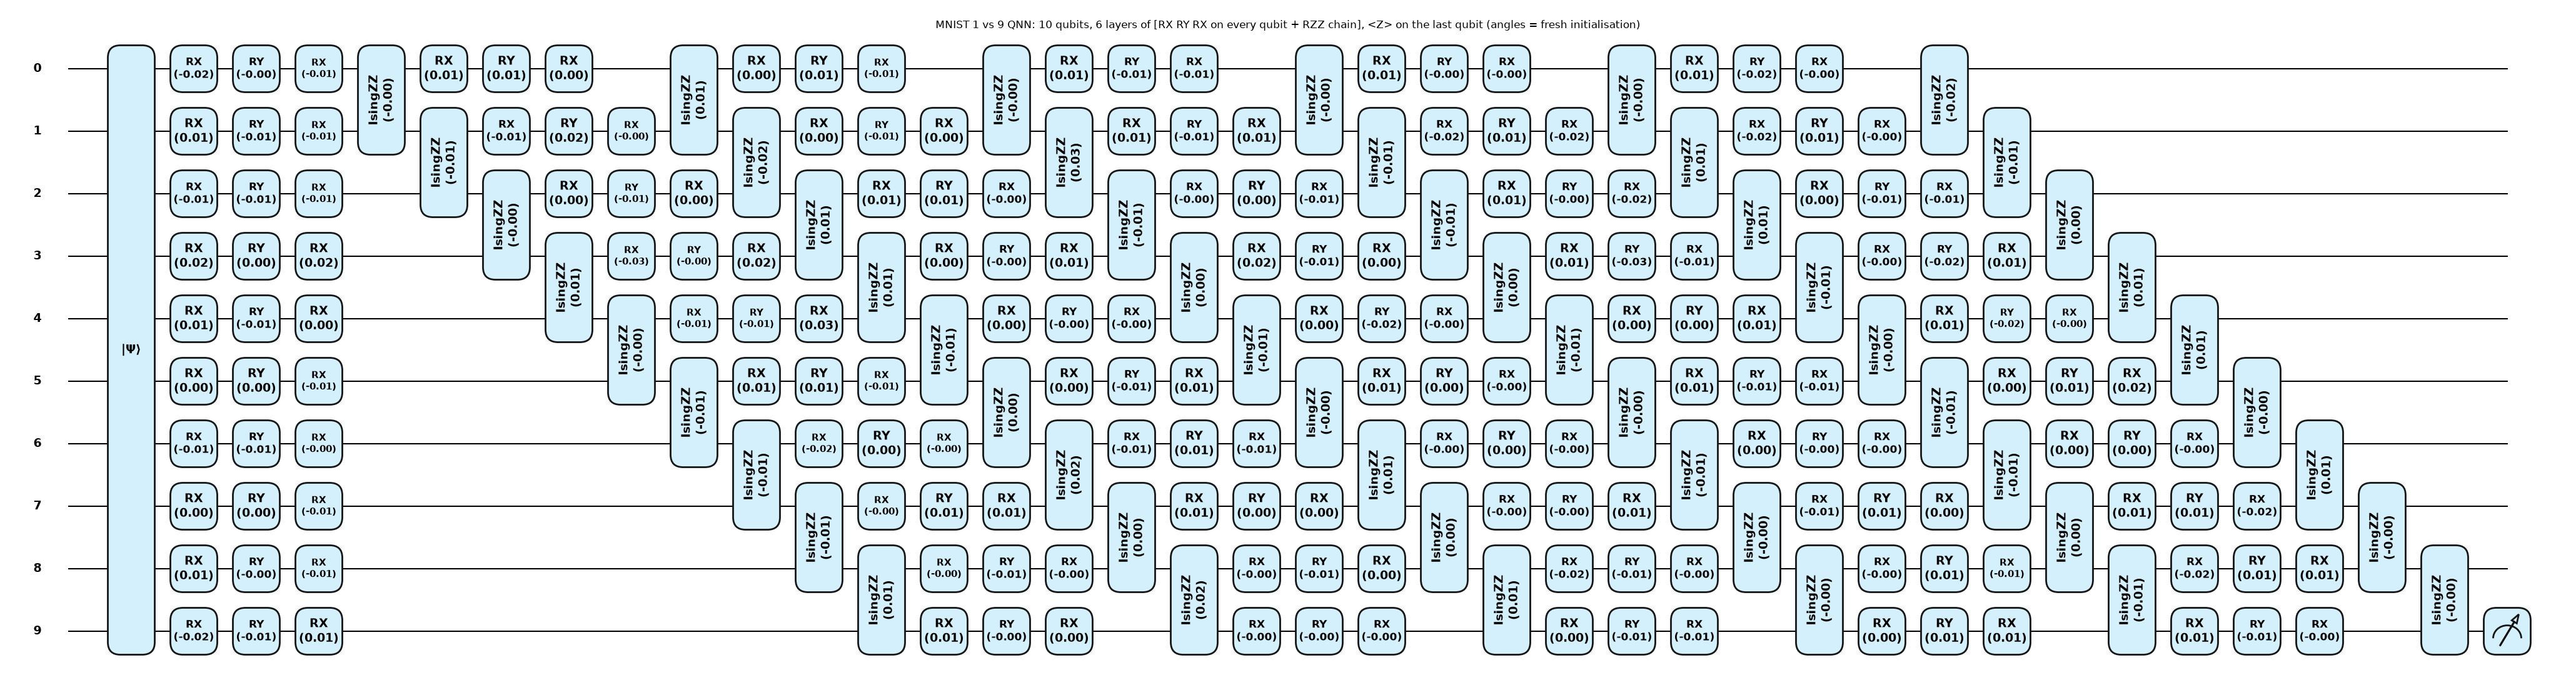

MNIST 1 vs 9 QNN: qubits = 10 | depth of the executed circuit (device gates) = 38 | trainable angles = 234 (= 6 layers x 30 rotation angles + 9 RZZ angles) | angles with a non-zero gradient (inside the light cone of <Z_last>) = 78
   gate counts: {'AmplitudeEmbedding': 1, 'RX': 120, 'RY': 60, 'IsingZZ': 54}


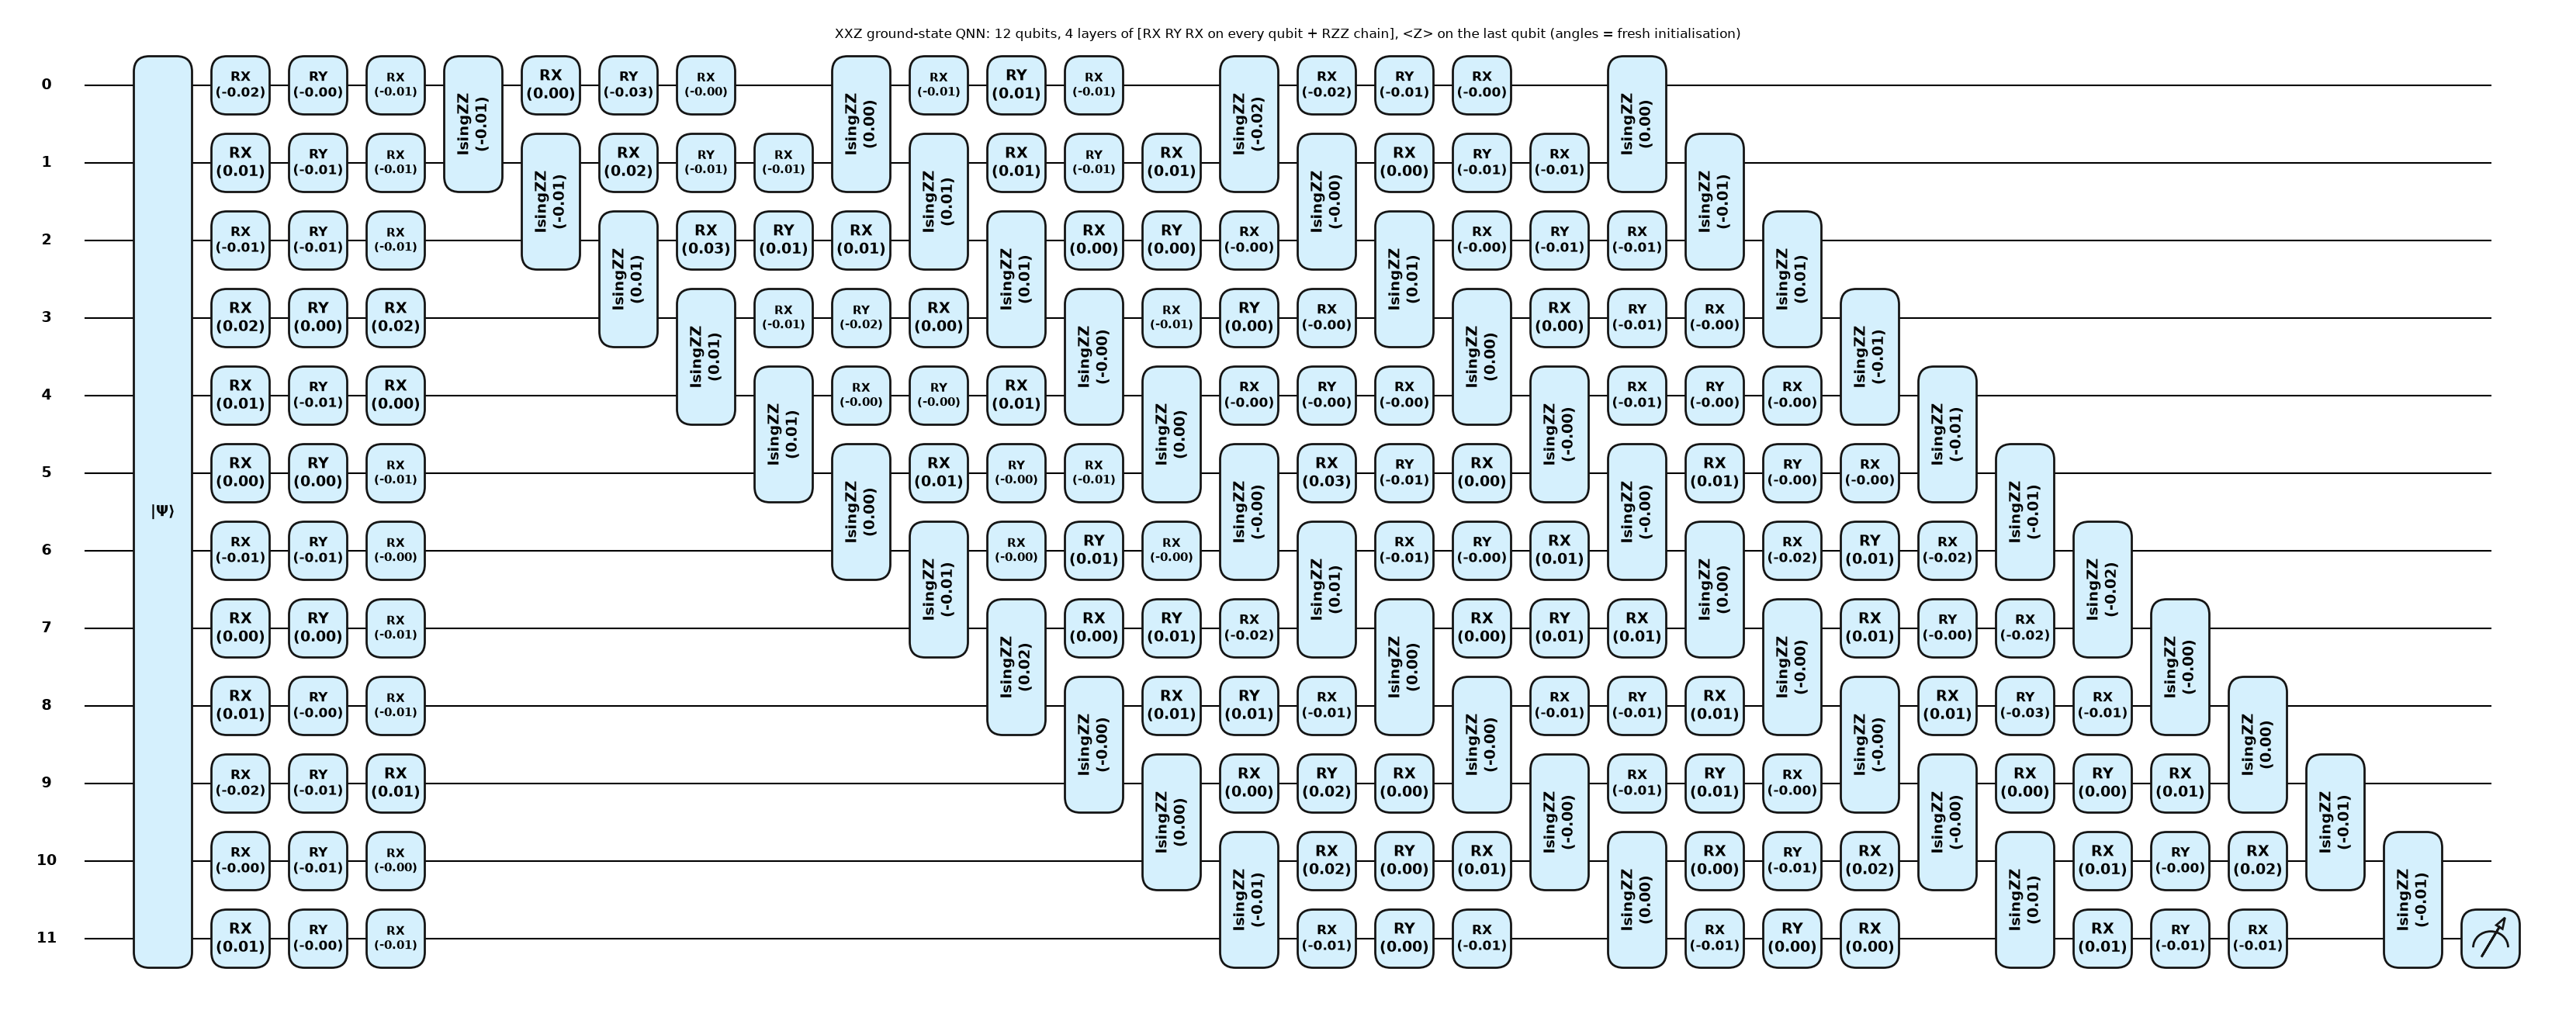

XXZ ground-state QNN: qubits = 12 | depth of the executed circuit (device gates) = 30 | trainable angles = 188 (= 4 layers x 36 rotation angles + 11 RZZ angles) | angles with a non-zero gradient (inside the light cone of <Z_last>) = 36
   gate counts: {'AmplitudeEmbedding': 1, 'RX': 96, 'RY': 48, 'IsingZZ': 44}


In [16]:
for k, title in [("mnist", "MNIST 1 vs 9 QNN"), ("xxz", "XXZ ground-state QNN")]:
    v, t = ARCH[k], TASKS[k]
    ens1 = QNNEnsemble(1, v["n"], v["depth"], seeds=[0])                                 # a freshly initialised model: angles ~ N(0, 0.01^2)
    amp1 = t["amp"](t["x"][:1])[0]
    fig, _ = qml.draw_mpl(QNODES[k], decimals=2, style="pennylane", fig_options=dict(figsize=(30 if k == "mnist" else 24, 0.62 * v["n"] + 1.0)))(amp1, ens1.theta[0].detach())
    fig.suptitle(f"{title}: {v['n']} qubits, {v['depth']} layers of [RX RY RX on every qubit + RZZ chain], <Z> on the last qubit (angles = fresh initialisation)", fontsize=12)
    plt.show()
    specs = qml.specs(QNODES[k], level="device")(amp1, ens1.theta[0].detach())
    res = specs.resources
    # parameters that can influence <Z_last>: the others sit outside the light cone of the measurement (e.g. the last RZZ layer commutes with Z)
    ens_g = QNNEnsemble(1, v["n"], v["depth"], init_std=1.0, seeds=[3])
    ens_g.logits(ens_g.reduced(t["amp"](t["x"][:4]), dtype=torch.float64)).sum().backward()
    n_eff = int((ens_g.theta.grad.abs() > 1e-12).sum())
    print(f"{title}: qubits = {v['n']} | depth of the executed circuit (device gates) = {res.depth} | trainable angles = {ens_g.P} "
          f"(= {v['depth']} layers x {3 * v['n']} rotation angles + {v['n'] - 1} RZZ angles) | angles with a non-zero gradient (inside the light cone of <Z_last>) = {n_eff}")
    print(f"   gate counts: {dict(res.gate_types)}")

## 3. Classical baselines on identical inputs

The paper compares the QNN with an MLP; its supplement also tests SVM, logistic regression, CNN and ResNet. Here we add three classical baselines trained on exactly the same corrupted labels and the same inputs as the MLP (SVC with RBF kernel, logistic regression, random forest),
and one baseline that matters for the interpretation: a logistic regression on the QNN's own features. The QNN output is *linear in the reduced density matrix* rho of the last qubits (<Z> = Tr(rho O)), so a linear classifier on rho is the natural classical model of the same function class.

In [17]:
# Other classical models on the SAME inputs as the MLP (the paper's Supplement reports that SVM, logistic regression, ... also degrade steadily under label noise).
def baseline_curves(task):
    """Validation accuracy of SVC(rbf), logistic regression and a random forest versus the label-flipping ratio, (len(ALPHAS), N_SEEDS) each."""
    Xtr, Xva = task["vec"](task["x"]).numpy(), task["vec"](task["xv"]).numpy()
    # the QNN's own features: its output is LINEAR in the reduced density matrix rho of the last wires, so a logistic regression on rho is the natural
    # classical model of the same function class (our addition; `# CHOICE`: features scaled by 2^k so that they are of order one)
    q_enc = QNNEnsemble(1, task["n"], task["cfg"]["qnn"]["depth"])
    def rho_feat(x):
        r = q_enc.reduced(task["amp"](x), dtype=torch.float64).numpy() * 2 ** q_enc.k
        return np.concatenate([r.real, r.imag], 1) if np.iscomplexobj(r) else r
    Rtr, Rva = rho_feat(task["x"]), rho_feat(task["xv"])
    out = {k: np.zeros((len(ALPHAS), N_SEEDS)) for k in ("SVC (rbf)", "Logistic regression", "Random forest", "Logistic regression on rho")}
    for ia, a in enumerate(ALPHAS):
        for s in range(N_SEEDS):
            y2, _ = flip_labels(task["y"], a, np.random.default_rng([SEED, s, int(round(a * 100)), 1]))          # the same corrupted labels as the MLP / QNN runs
            if len(np.unique(y2)) < 2:
                continue
            out["SVC (rbf)"][ia, s] = SVC(kernel="rbf", C=1.0, gamma="scale").fit(Xtr, y2).score(Xva, task["yv"])
            out["Logistic regression"][ia, s] = LogisticRegression(max_iter=2000, C=1.0).fit(Xtr, y2).score(Xva, task["yv"])
            out["Random forest"][ia, s] = RandomForestClassifier(n_estimators=50, random_state=SEED + s, n_jobs=1).fit(Xtr, y2).score(Xva, task["yv"])
            out["Logistic regression on rho"][ia, s] = LogisticRegression(max_iter=500, C=1.0).fit(Rtr, y2).score(Rva, task["yv"])
    return out


t0 = time.time()
BASELINES = {k: baseline_curves(TASKS[k]) for k in TASKS}
print(f"classical baselines trained in {time.time() - t0:.0f} s")
print(pd.concat({k: pd.DataFrame({m: v.mean(1) for m, v in d.items()}, index=[f"alpha={a}" for a in ALPHAS]) for k, d in BASELINES.items()}, axis=1).round(3).to_string())

classical baselines trained in 97 s
              mnist                                                                    xxz                                                             
          SVC (rbf) Logistic regression Random forest Logistic regression on rho SVC (rbf) Logistic regression Random forest Logistic regression on rho
alpha=0.0     0.988               0.987         0.986                      0.986     0.988               0.476         0.976                      1.000
alpha=0.2     0.988               0.984         0.972                      0.824     0.875               0.470         0.845                      0.964
alpha=0.4     0.909               0.870         0.684                      0.587     0.720               0.542         0.667                      0.952
alpha=0.5     0.456               0.402         0.452                      0.496     0.476               0.488         0.476                      0.613
alpha=0.6     0.158               0.190         0.32

## 4. Experiment 1: resilience to label flipping and feature randomization (Fig. 2)

For each noise ratio alpha and each seed a fresh model is trained on the corrupted training set (accuracy on that corrupted set = "training accuracy") and evaluated on the clean validation set. Label flipping inverts an even number of labels, half per class; feature randomization replaces
the chosen feature vectors by random unit vectors and keeps the labels. All models of a chunk are trained side by side as independent ensemble members; the MLP and the QNN see the *same* corrupted samples for the same (alpha, seed).

In [18]:
def phase_diagram(task, kind, corruption):
    """Train one model per (alpha, seed) on the corrupted training set and return (train accuracy on the corrupted set, clean validation accuracy):
    array of shape (len(ALPHAS), N_SEEDS, 2). All models of a chunk are trained side by side (they are independent)."""
    cfg = task["cfg"][kind]
    combos = [(a, s) for a in ALPHAS for s in range(N_SEEDS)]
    res = np.zeros((len(combos), 2))
    for c0 in range(0, len(combos), CHUNK[kind]):
        part = combos[c0:c0 + CHUNK[kind]]
        Xn, Ys = [], []
        for a, s in part:
            rng = np.random.default_rng([SEED, s, int(round(a * 100)), 1 if corruption == "flip" else 2])
            if corruption == "flip":
                y2, _ = flip_labels(task["y"], a, rng); x2 = task["x"]
            else:
                x2, _ = randomize_features(task["x"], task["y"], a, rng); y2 = task["y"]
            Xn.append(x2); Ys.append(y2)
        Y = torch.tensor(np.stack(Ys), dtype=torch.float64)
        mseeds = [SEED + 7919 * s + int(round(a * 100)) for a, s in part]
        if kind == "qnn":
            m = QNNEnsemble(len(part), task["n"], cfg["depth"], seeds=mseeds)
            enc = lambda x: m.reduced(task["amp"](x), dtype=task["rho_dtype"])
        else:
            m = MLPEnsemble(len(part), task["vec"](task["x"][:1]).shape[1], cfg["hidden"], seeds=mseeds, dtype=task["mlp_dtype"])
            enc = lambda x: task["vec"](x)
        X = enc(Xn[0]) if corruption == "flip" else torch.stack([enc(x) for x in Xn])          # label flipping: one shared feature matrix
        out = fit_ensemble(m, kind, X, Y, cfg["epochs"], cfg["bs"], cfg["lr"], seed=SEED + c0, eval_sets={"val_acc": (enc(task["xv"]), task["yv_t"])})
        res[c0:c0 + len(part)] = np.stack([out["train_acc"], out["val_acc"]], 1)
    return res.reshape(len(ALPHAS), N_SEEDS, 2)


RES1, TIMES1 = {}, {}
for tk in ("mnist", "xxz"):
    for kind in ("mlp", "qnn"):
        for corruption in ("flip", "rand"):
            t0 = time.time()
            RES1[(tk, kind, corruption)] = phase_diagram(TASKS[tk], kind, corruption)
            TIMES1[(tk, kind, corruption)] = time.time() - t0
            v = RES1[(tk, kind, corruption)][:, :, 1].mean(1)
            print(f"{tk:5s} {kind.upper():3s} {corruption:4s}: {time.time() - t0:5.0f} s | mean validation accuracy over alpha {list(ALPHAS)}: {np.round(v, 3).tolist()}")

mnist MLP flip:    51 s | mean validation accuracy over alpha [0.0, 0.2, 0.4, 0.5, 0.6, 0.8]: [0.99, 0.824, 0.6, 0.516, 0.407, 0.152]


mnist MLP rand:    32 s | mean validation accuracy over alpha [0.0, 0.2, 0.4, 0.5, 0.6, 0.8]: [0.99, 0.987, 0.988, 0.987, 0.99, 0.988]


mnist QNN flip:   119 s | mean validation accuracy over alpha [0.0, 0.2, 0.4, 0.5, 0.6, 0.8]: [0.934, 0.952, 0.84, 0.489, 0.22, 0.028]


mnist QNN rand:    90 s | mean validation accuracy over alpha [0.0, 0.2, 0.4, 0.5, 0.6, 0.8]: [0.934, 0.943, 0.919, 0.932, 0.951, 0.932]


xxz   MLP flip:   112 s | mean validation accuracy over alpha [0.0, 0.2, 0.4, 0.5, 0.6, 0.8]: [0.994, 0.839, 0.595, 0.512, 0.423, 0.196]


xxz   MLP rand:    99 s | mean validation accuracy over alpha [0.0, 0.2, 0.4, 0.5, 0.6, 0.8]: [0.994, 0.994, 0.994, 0.946, 0.917, 0.863]


xxz   QNN flip:   110 s | mean validation accuracy over alpha [0.0, 0.2, 0.4, 0.5, 0.6, 0.8]: [0.976, 0.994, 0.952, 0.869, 0.161, 0.018]


xxz   QNN rand:   133 s | mean validation accuracy over alpha [0.0, 0.2, 0.4, 0.5, 0.6, 0.8]: [0.976, 0.988, 1.0, 1.0, 0.988, 0.952]


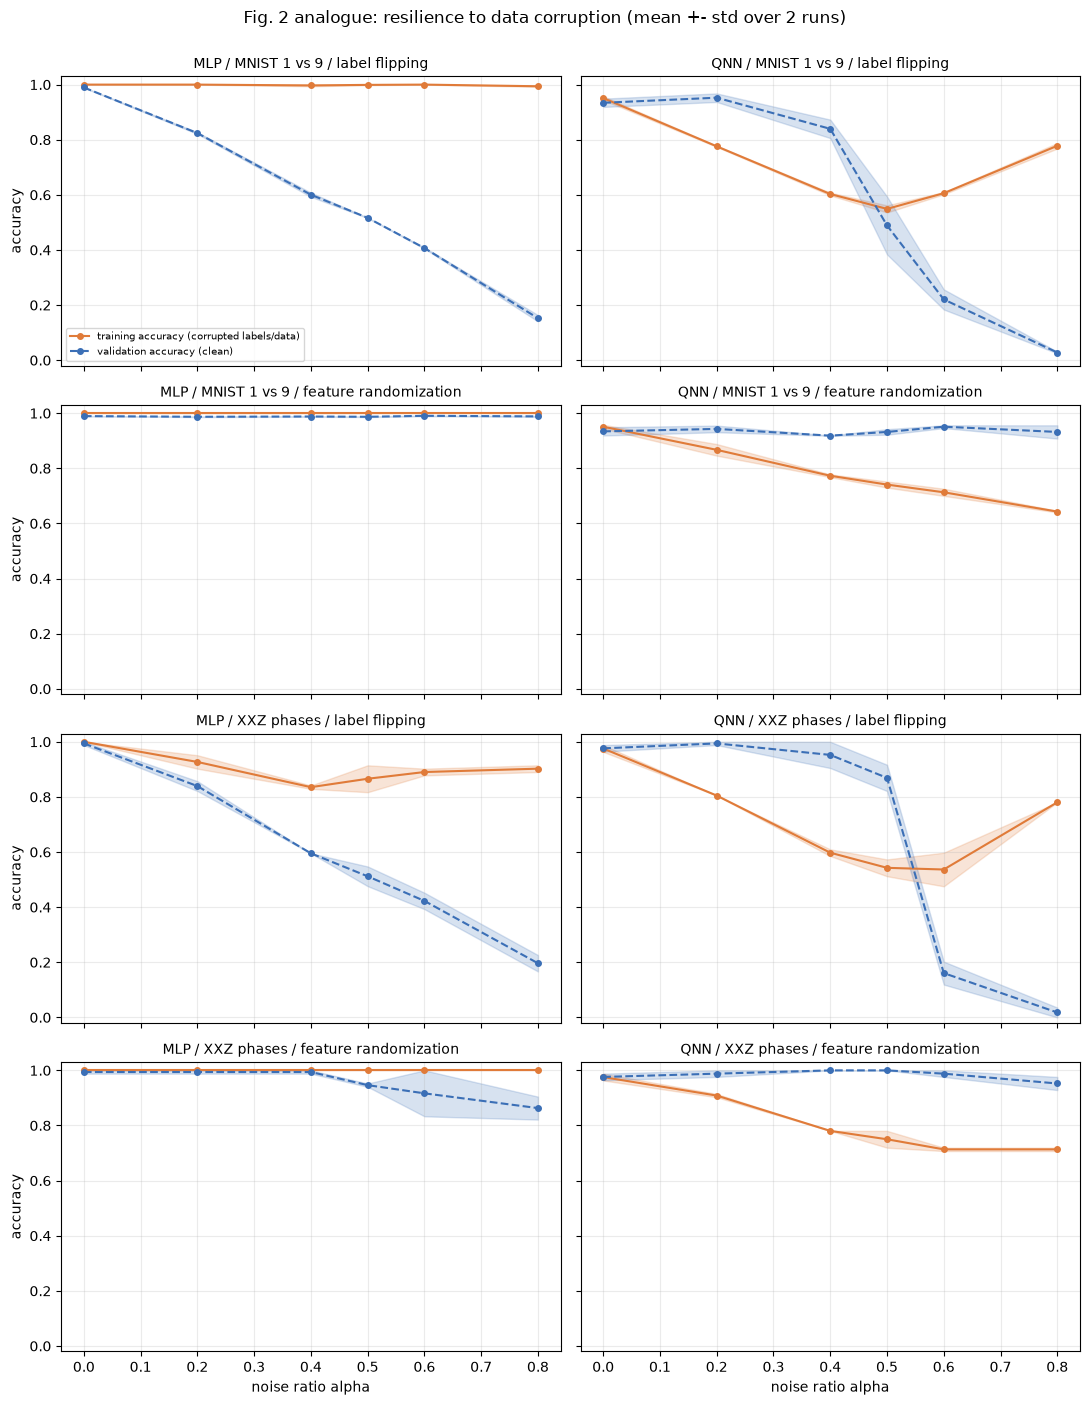

Mean clean-validation accuracy:
           mnist/MLP/flip  mnist/MLP/rand  mnist/QNN/flip  mnist/QNN/rand  xxz/MLP/flip  xxz/MLP/rand  xxz/QNN/flip  xxz/QNN/rand
alpha=0.0           0.990           0.990           0.934           0.934         0.994         0.994         0.976         0.976
alpha=0.2           0.824           0.987           0.952           0.943         0.839         0.994         0.994         0.988
alpha=0.4           0.600           0.988           0.840           0.919         0.595         0.994         0.952         1.000
alpha=0.5           0.516           0.987           0.489           0.932         0.512         0.946         0.869         1.000
alpha=0.6           0.407           0.990           0.220           0.951         0.423         0.917         0.161         0.988
alpha=0.8           0.152           0.988           0.028           0.932         0.196         0.863         0.018         0.952

Mean training accuracy on the corrupted training set (1.0

In [19]:
def mean_std(a):
    return a.mean(1), a.std(1)

fig, axes = plt.subplots(4, 2, figsize=(11, 14), sharex=True, sharey=True)
for ti, tk in enumerate(("mnist", "xxz")):
    for ri, corruption in enumerate(("flip", "rand")):
        for ci, kind in enumerate(("mlp", "qnn")):
            ax = axes[ti * 2 + ri, ci]
            r = RES1[(tk, kind, corruption)]
            for j, (nm, col, ls) in enumerate([("training accuracy (corrupted labels/data)", "#E07B39", "-"), ("validation accuracy (clean)", "#3B6FB6", "--")]):
                m_, s_ = mean_std(r[:, :, j])
                ax.plot(ALPHAS, m_, ls, color=col, marker="o", ms=4, label=nm); ax.fill_between(ALPHAS, m_ - s_, m_ + s_, color=col, alpha=0.2)
            ax.set_title(f"{kind.upper()} / {'MNIST 1 vs 9' if tk == 'mnist' else 'XXZ phases'} / {'label flipping' if corruption == 'flip' else 'feature randomization'}", fontsize=10)
            ax.set_ylim(-0.02, 1.03)
            if ri == 1 and ti == 1: ax.set_xlabel("noise ratio alpha")
            if ci == 0: ax.set_ylabel("accuracy")
axes[0, 0].legend(fontsize=7, loc="lower left")
plt.suptitle(f"Fig. 2 analogue: resilience to data corruption (mean +- std over {N_SEEDS} runs)", y=1.0)
plt.tight_layout(); plt.show()

summary1 = pd.DataFrame({f"{tk}/{kind.upper()}/{c}": RES1[(tk, kind, c)][:, :, 1].mean(1) for tk in ("mnist", "xxz") for kind in ("mlp", "qnn") for c in ("flip", "rand")}, index=[f"alpha={a}" for a in ALPHAS]).round(3)
print("Mean clean-validation accuracy:")
print(summary1.to_string())
summary1_train = pd.DataFrame({f"{tk}/{kind.upper()}/{c}": RES1[(tk, kind, c)][:, :, 0].mean(1) for tk in ("mnist", "xxz") for kind in ("mlp", "qnn") for c in ("flip", "rand")}, index=[f"alpha={a}" for a in ALPHAS]).round(3)
print("\nMean training accuracy on the corrupted training set (1.0 = the model memorises even the wrong labels; 1 - alpha = it ignores them):")
print(summary1_train.to_string())

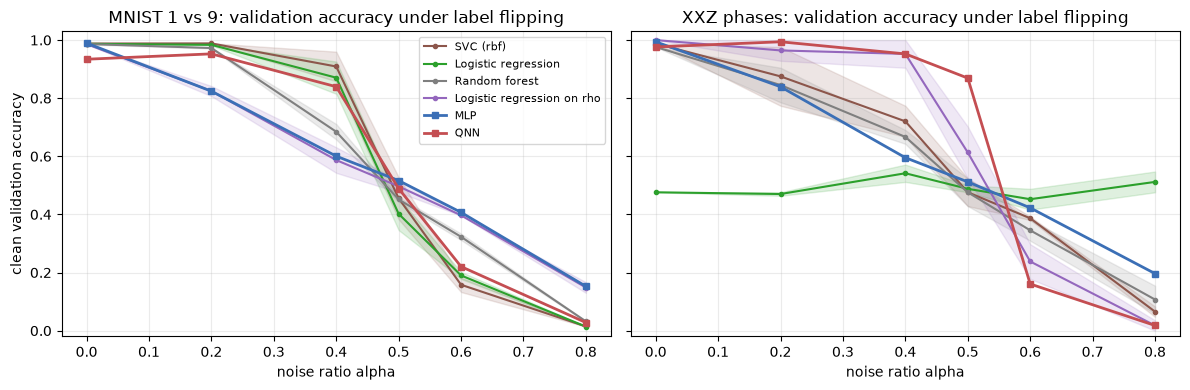

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, tk in zip(axes, ("mnist", "xxz")):
    for nm, col in [("SVC (rbf)", "#8C564B"), ("Logistic regression", "#2CA02C"), ("Random forest", "#7F7F7F"), ("Logistic regression on rho", "#9467BD")]:
        m_, s_ = mean_std(BASELINES[tk][nm]); ax.plot(ALPHAS, m_, "-o", ms=3, color=col, label=nm); ax.fill_between(ALPHAS, m_ - s_, m_ + s_, color=col, alpha=0.15)
    for kind, col in [("mlp", "#3B6FB6"), ("qnn", "#C44E52")]:
        m_, s_ = mean_std(RES1[(tk, kind, "flip")][:, :, 1]); ax.plot(ALPHAS, m_, "-s", ms=4, lw=2, color=col, label=kind.upper())
    ax.set_title(f"{'MNIST 1 vs 9' if tk == 'mnist' else 'XXZ phases'}: validation accuracy under label flipping"); ax.set_xlabel("noise ratio alpha"); ax.set_ylim(-0.02, 1.03)
axes[0].set_ylabel("clean validation accuracy"); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

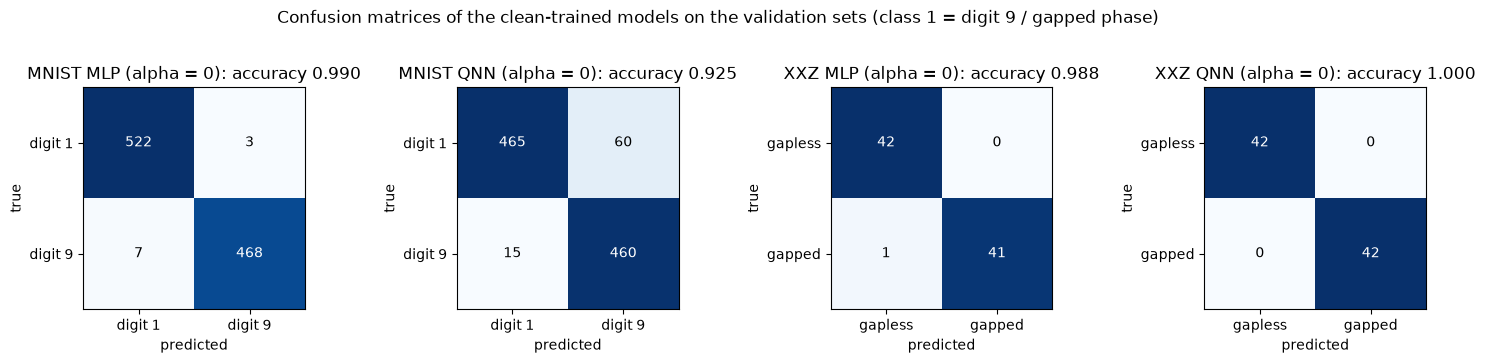

 task model  validation_accuracy  recall_class0  recall_class1  train_seconds
mnist   MLP                0.990          0.994          0.985            9.9
mnist   QNN                0.925          0.886          0.968           25.3
  xxz   MLP                0.988          1.000          0.976           15.7
  xxz   QNN                1.000          1.000          1.000           25.6

Wall-clock time of the whole Experiment 1 sweep (all noise ratios and seeds, models trained side by side), seconds:
mnist/MLP/flip     51
mnist/MLP/rand     32
mnist/QNN/flip    119
mnist/QNN/rand     90
xxz/MLP/flip      112
xxz/MLP/rand       99
xxz/QNN/flip      110
xxz/QNN/rand      133


In [21]:
def clean_model_confusion(task, kind, seed=SEED):
    """Train one model on the clean training set (same settings as alpha = 0 above) and return the 2 x 2 confusion matrix on the validation set."""
    cfg = task["cfg"][kind]
    Y = task["y_t"][None]
    if kind == "qnn":
        m = QNNEnsemble(1, task["n"], cfg["depth"], seeds=[seed]); enc = lambda x: m.reduced(task["amp"](x), dtype=task["rho_dtype"])
    else:
        m = MLPEnsemble(1, task["vec"](task["x"][:1]).shape[1], cfg["hidden"], seeds=[seed], dtype=task["mlp_dtype"]); enc = task["vec"]
    t0 = time.time()
    fit_ensemble(m, kind, enc(task["x"]), Y, cfg["epochs"], cfg["bs"], cfg["lr"], seed=seed)
    with torch.no_grad():
        pred = (m.logits(enc(task["xv"]))[0] > 0).numpy().astype(int)
    cm = np.zeros((2, 2), int)
    for t_, p_ in zip(task["yv"], pred): cm[t_, p_] += 1
    return cm, time.time() - t0


fig, axes = plt.subplots(1, 4, figsize=(15, 3.4))
rows = []
for ax, (tk, kind) in zip(axes, [("mnist", "mlp"), ("mnist", "qnn"), ("xxz", "mlp"), ("xxz", "qnn")]):
    cm, dt = clean_model_confusion(TASKS[tk], kind)
    names = ["digit 1", "digit 9"] if tk == "mnist" else ["gapless", "gapped"]
    ax.imshow(cm, cmap="Blues"); ax.grid(False)
    for i in range(2):
        for j in range(2): ax.text(j, i, str(cm[i, j]), ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_xticks([0, 1]); ax.set_xticklabels(names); ax.set_yticks([0, 1]); ax.set_yticklabels(names); ax.set_xlabel("predicted"); ax.set_ylabel("true")
    acc = np.trace(cm) / cm.sum()
    ax.set_title(f"{tk.upper()} {kind.upper()} (alpha = 0): accuracy {acc:.3f}")
    rows.append(dict(task=tk, model=kind.upper(), validation_accuracy=round(acc, 3), recall_class0=round(cm[0, 0] / cm[0].sum(), 3), recall_class1=round(cm[1, 1] / cm[1].sum(), 3), train_seconds=round(dt, 1)))
plt.suptitle("Confusion matrices of the clean-trained models on the validation sets (class 1 = digit 9 / gapped phase)", y=1.04); plt.tight_layout(); plt.show()
print(pd.DataFrame(rows).to_string(index=False))
print("\nWall-clock time of the whole Experiment 1 sweep (all noise ratios and seeds, models trained side by side), seconds:")
print(pd.Series({f"{tk}/{kind.upper()}/{c}": round(v) for (tk, kind, c), v in TIMES1.items()}).to_string())

## 5. Experiment 2: quantum machine unlearning (Figs. 3a, 3b)

A model is first trained on the polluted set (30 % flipped labels, the flipped samples being D_forget). Then four procedures start (one unlearning step = one epoch over the retain set):
**Retrain** (random initialisation, retain set only), **Finetune** (continue on the retain set), **Scrub** (retain cross-entropy minus 0.2 x the teacher/student term on the forget set) and **Grad-Asc** (retain cross-entropy minus 0.2 x the cross-entropy on the polluted forget set).
Accuracy on the clean validation set is recorded at the start of every epoch (step 0 = the polluted starting point; for Retrain, a random model).

In [22]:
def run_unlearning(task, kind):
    """Pre-train S polluted models (label flipping, alpha = UNL_ALPHA; the flipped samples are the forget set), then run Retrain / Finetune / Scrub /
    Gradient ascent for each of them (one unlearning step = one epoch over the retain set). Returns accuracy trajectories (4, S, UNL_EPOCHS)."""
    u = UNL[task["name"]][kind]; pre = u["pre"]; S = UNL_SEEDS; N = len(task["y"])
    qdepth = pre.get("depth")
    if kind == "qnn":
        enc_model = QNNEnsemble(1, task["n"], qdepth)
        enc = lambda x: enc_model.reduced(task["amp"](x), dtype=task["rho_dtype"])
        fresh = lambda R: QNNEnsemble(R, task["n"], qdepth, seeds=[SEED + 977 * r + 5 for r in range(R)])
    else:
        enc = task["vec"]
        d_in = task["vec"](task["x"][:1]).shape[1]
        fresh = lambda R: MLPEnsemble(R, d_in, pre["hidden"], seeds=[SEED + 977 * r + 5 for r in range(R)], dtype=task["mlp_dtype"])
    Xall, Xv = enc(task["x"]), enc(task["xv"])
    y_t = torch.tensor(task["y"], dtype=torch.float64)
    data, ypols = [], []
    for s in range(S):
        y_pol, fidx = flip_labels(task["y"], UNL_ALPHA, np.random.default_rng([SEED, s, 3000]))
        mask = np.zeros(N, bool); mask[fidx] = True
        mt = torch.tensor(mask)
        data.append(dict(Xr=Xall[~mt], yr=y_t[~mt], Xf=Xall[mt], yf_clean=y_t[mt], yf_pollu=torch.tensor(y_pol[mask], dtype=torch.float64)))
        ypols.append(y_pol)
    data = {**{s: d for s, d in enumerate(data)}, "Xv": Xv, "yv": task["yv_t"]}
    teacher = fresh(S)                                                                       # the polluted models, trained on all of D_train
    fit_ensemble(teacher, kind, Xall, torch.tensor(np.stack(ypols), dtype=torch.float64), pre["epochs"], pre["bs"], pre["lr"], seed=SEED + 1)
    with torch.no_grad():
        start = dict(val=accuracy(teacher.logits(Xv), task["yv_t"]).numpy(),
                     forget=np.array([accuracy(teacher.logits(Xall[torch.tensor(np.where(ypols[s] != task["y"])[0])]), y_t[torch.tensor(np.where(ypols[s] != task["y"])[0])])[s].item() for s in range(S)]))
    traj = unlearn_ensemble(kind, fresh, teacher, data, UNL_EPOCHS, u["bs"], u["lr"], W_SCRUB, W_GA, seed=SEED + 2)
    return traj, start


RES2 = {}
for tk in ("mnist", "xxz"):
    for kind in ("mlp", "qnn"):
        t0 = time.time()
        RES2[(tk, kind)] = run_unlearning(TASKS[tk], kind)
        traj, start = RES2[(tk, kind)]
        print(f"{tk:5s} {kind.upper():3s}: {time.time() - t0:4.0f} s | polluted model: validation accuracy {start['val'].mean():.3f}, accuracy on the clean forget set {start['forget'].mean():.3f}"
              f" | after {UNL_EPOCHS} steps the validation accuracy is " + ", ".join(f"{m} {traj['val'][i, :, -1].mean():.3f}" for i, m in enumerate(METHODS)))

mnist MLP:   14 s | polluted model: validation accuracy 0.694, accuracy on the clean forget set 0.023 | after 25 steps the validation accuracy is Retrain 0.970, Finetune 0.889, Scrub 0.827, Grad-Asc 0.869


mnist QNN:   44 s | polluted model: validation accuracy 0.958, accuracy on the clean forget set 0.943 | after 25 steps the validation accuracy is Retrain 0.691, Finetune 0.935, Scrub 0.940, Grad-Asc 0.905


xxz   MLP:   40 s | polluted model: validation accuracy 0.726, accuracy on the clean forget set 0.229 | after 25 steps the validation accuracy is Retrain 0.988, Finetune 0.994, Scrub 0.970, Grad-Asc 0.988


xxz   QNN:   62 s | polluted model: validation accuracy 1.000, accuracy on the clean forget set 1.000 | after 25 steps the validation accuracy is Retrain 0.982, Finetune 1.000, Scrub 0.976, Grad-Asc 0.988


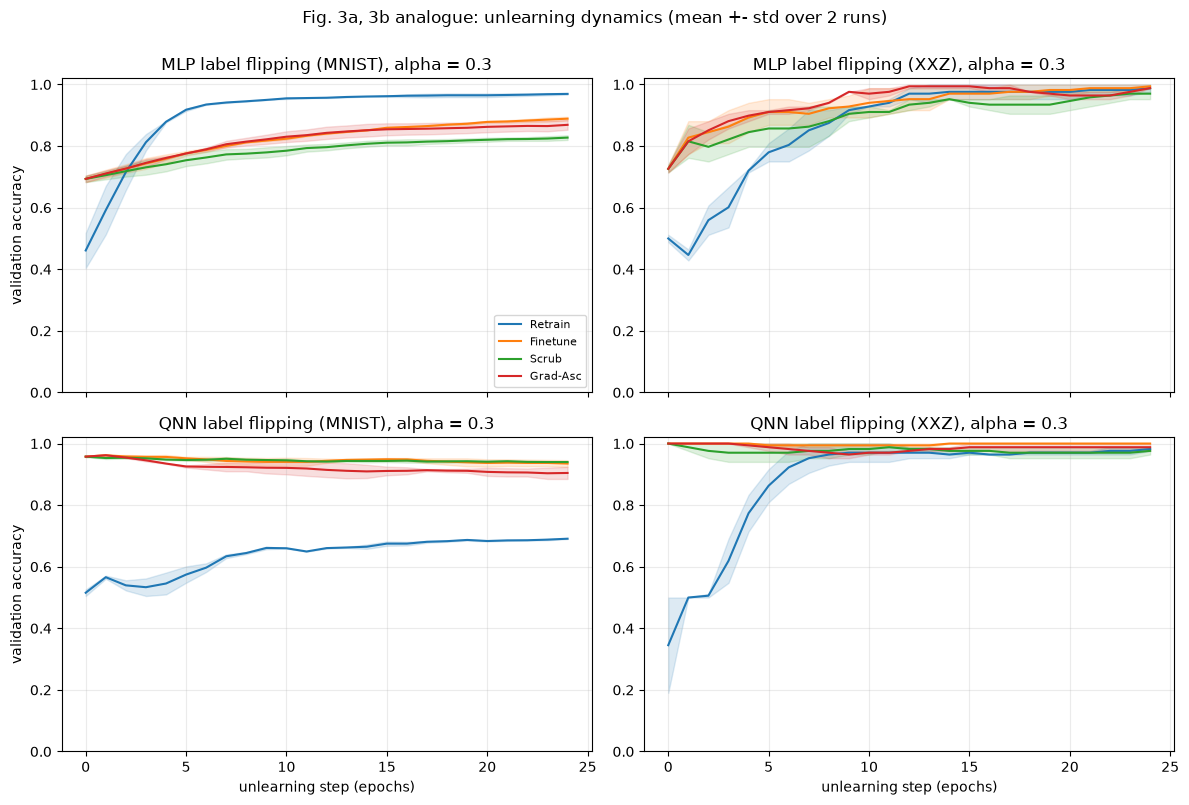

 task model   method  val_step0  val_mean_first10  val_final  forget_acc_final  retain_acc_final
mnist   MLP  Retrain      0.461             0.815      0.970             0.933             0.971
mnist   MLP Finetune      0.694             0.763      0.889             0.507             1.000
mnist   MLP    Scrub      0.694             0.743      0.827             0.487             0.971
mnist   MLP Grad-Asc      0.694             0.765      0.869             0.520             0.984
mnist   QNN  Retrain      0.516             0.581      0.691             0.603             0.594
mnist   QNN Finetune      0.958             0.952      0.935             0.943             0.954
mnist   QNN    Scrub      0.958             0.950      0.940             0.923             0.956
mnist   QNN Grad-Asc      0.958             0.937      0.905             0.933             0.937
  xxz   MLP  Retrain      0.500             0.705      0.988             0.958             1.000
  xxz   MLP Finetune      0.72

In [23]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True)
cols = {"Retrain": "#1F77B4", "Finetune": "#FF7F0E", "Scrub": "#2CA02C", "Grad-Asc": "#D62728"}
for ti, tk in enumerate(("mnist", "xxz")):
    for ci, kind in enumerate(("mlp", "qnn")):
        ax = axes[ci, ti]
        traj, start = RES2[(tk, kind)]
        for i, mname in enumerate(METHODS):
            v = traj["val"][i]
            ax.plot(np.arange(v.shape[1]), v.mean(0), color=cols[mname], label=mname); ax.fill_between(np.arange(v.shape[1]), v.mean(0) - v.std(0), v.mean(0) + v.std(0), color=cols[mname], alpha=0.15)
        ax.set_title(f"{kind.upper()} label flipping ({'MNIST' if tk == 'mnist' else 'XXZ'}), alpha = {UNL_ALPHA}"); ax.set_ylim(0.0, 1.02)
        if ci == 1: ax.set_xlabel("unlearning step (epochs)")
        if ti == 0: ax.set_ylabel("validation accuracy")
axes[0, 0].legend(fontsize=8, loc="lower right")
plt.suptitle(f"Fig. 3a, 3b analogue: unlearning dynamics (mean +- std over {UNL_SEEDS} runs)", y=1.0)
plt.tight_layout(); plt.show()

rows = []
for (tk, kind), (traj, start) in RES2.items():
    for i, mname in enumerate(METHODS):
        v = traj["val"][i]
        rows.append(dict(task=tk, model=kind.upper(), method=mname, val_step0=v[:, 0].mean(), val_mean_first10=v[:, :10].mean(), val_final=v[:, -1].mean(),
                         forget_acc_final=traj["forget"][i][:, -1].mean(), retain_acc_final=traj["retain"][i][:, -1].mean()))
UNL_TABLE = pd.DataFrame(rows).round(3)
print(UNL_TABLE.to_string(index=False))

## 6. Experiment 3: the Landscape Roughening Ratio (Fig. 3d)

Models are trained on 70 % of the 500 MNIST images with alpha = 0 (clean) and with label flipping, then the trace of the Hessian of the mean cross-entropy on 100 clean held-out images is estimated at the trained parameters with Hutchinson's method
(Tr H = E[v^T H v] for random +-1 vectors v; each Hessian-vector product is an exact double back-propagation). LRR = Tr H(noisy) / mean over seeds of Tr H(clean). Values far above 1 mean that the landscape sharpened to memorise the noise.

In [24]:
def run_lrr(kind):
    """Train models on the 70 % split of the 500 MNIST images (alpha = 0 and each alpha of LRR_ALPHAS, LRR_SEEDS seeds), then estimate the trace of the Hessian of the
    mean cross-entropy on LRR_HESS_SAMPLES clean held-out images at the trained parameters; LRR = Tr H(noisy) / mean over seeds of Tr H(clean)."""
    from sklearn.model_selection import train_test_split
    task = TASKS["mnist"]; alphas = (0.0,) + tuple(LRR_ALPHAS)
    if kind == "qnn":
        enc_model = QNNEnsemble(1, task["n"], LRR_QNN_DEPTH)
        enc = lambda x: enc_model.reduced(task["amp"](x), dtype=torch.float32)
    else:
        enc = lambda x: task["vec"](x).to(torch.float64)
    Xall = enc(task["x"])
    Xtr, Ytr, Xh, Yh, order = [], [], [], [], []
    for a in alphas:
        for s in range(LRR_SEEDS):
            itr, ite = train_test_split(np.arange(len(task["y"])), test_size=0.3, stratify=task["y"], random_state=SEED + s)
            rng = np.random.default_rng([SEED, s, int(round(a * 100)), 4])
            y2, _ = flip_labels(task["y"][itr], a, rng)
            hs = np.random.default_rng([SEED, s, 5]).choice(ite, LRR_HESS_SAMPLES, replace=False)
            Xtr.append(Xall[itr]); Ytr.append(torch.tensor(y2, dtype=torch.float64)); Xh.append(Xall[hs]); Yh.append(torch.tensor(task["y"][hs], dtype=torch.float64))
            order.append((a, s))
    Xtr, Ytr, Xh, Yh = torch.stack(Xtr), torch.stack(Ytr), torch.stack(Xh), torch.stack(Yh)
    R = len(order); seeds = [SEED + 313 * s + int(round(a * 100)) for a, s in order]
    if kind == "qnn":
        m = QNNEnsemble(R, task["n"], LRR_QNN_DEPTH, seeds=seeds)
    else:
        m = MLPEnsemble(R, Xall.shape[1], LRR_MLP_HIDDEN, seeds=seeds, dtype=torch.float64)
    out = fit_ensemble(m, kind, Xtr, Ytr, LRR_TRAIN["epochs"], LRR_TRAIN["bs"], LRR_TRAIN["lr"], seed=SEED + 3, eval_sets={"held_out_acc": (Xh, Yh)})
    tr = hessian_trace(m, Xh, Yh, n_probe=LRR_PROBES, seed=SEED + 4)
    df = pd.DataFrame(dict(alpha=[a for a, s in order], seed=[s for a, s in order], trace=tr, train_acc=out["train_acc"], held_out_acc=out["held_out_acc"]))
    base = df[df.alpha == 0.0].trace.mean()
    df["LRR"] = df.trace / base
    return df, m, (Xh, Yh)


LRR = {}
for kind in ("mlp", "qnn"):
    t0 = time.time()
    LRR[kind] = run_lrr(kind)
    print(f"{kind.upper()}: {time.time() - t0:.0f} s")
    print(LRR[kind][0].groupby("alpha")[["trace", "train_acc", "held_out_acc", "LRR"]].agg(["mean", "std"]).round(3).to_string())

MLP: 39 s
        trace        train_acc        held_out_acc             LRR        
         mean    std      mean    std         mean    std     mean     std
alpha                                                                     
0.0     0.201  0.069     1.000  0.000        0.985  0.021    1.000   0.346
0.2     6.392  0.607     0.943  0.008        0.920  0.000   31.867   3.026
0.4    27.566  5.098     0.973  0.034        0.555  0.092  137.435  25.417


QNN: 146 s
        trace        train_acc        held_out_acc           LRR       
         mean    std      mean    std         mean    std   mean    std
alpha                                                                  
0.0    10.546  2.345     0.947  0.006        0.945  0.021  1.000  0.222
0.2     9.438  0.547     0.771  0.004        0.970  0.014  0.895  0.052
0.4     6.211  1.327     0.617  0.016        0.835  0.007  0.589  0.126


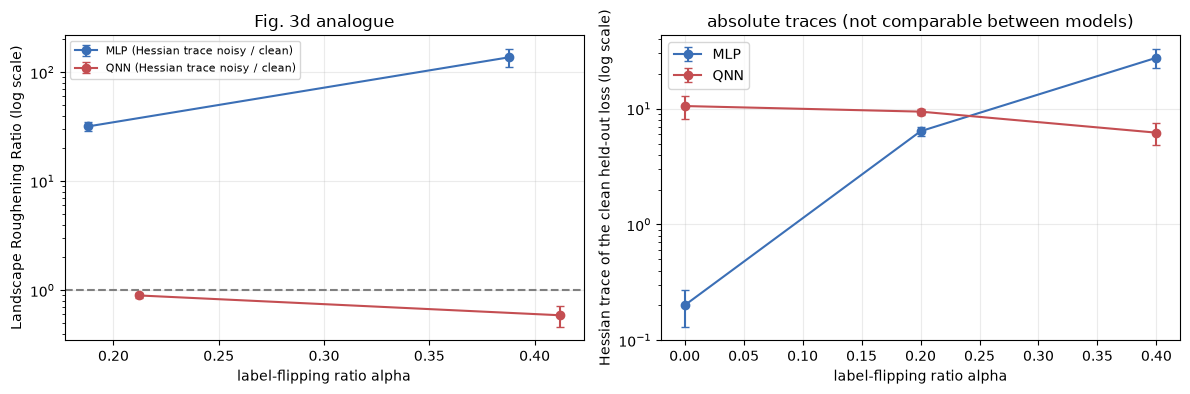

In [25]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for kind, col, off in [("mlp", "#3B6FB6", -0.012), ("qnn", "#C44E52", 0.012)]:
    df = LRR[kind][0]; g = df[df.alpha > 0].groupby("alpha").LRR
    ax[0].errorbar(g.mean().index + off, g.mean().values, yerr=g.std().values, fmt="-o", color=col, capsize=3, label=f"{kind.upper()} (Hessian trace noisy / clean)")
ax[0].axhline(1.0, color="grey", ls="--"); ax[0].set_yscale("log"); ax[0].set_xlabel("label-flipping ratio alpha"); ax[0].set_ylabel("Landscape Roughening Ratio (log scale)")
ax[0].set_title("Fig. 3d analogue"); ax[0].legend(fontsize=8)
for kind, col in [("mlp", "#3B6FB6"), ("qnn", "#C44E52")]:
    df = LRR[kind][0]; g = df.groupby("alpha").trace
    ax[1].errorbar(g.mean().index, g.mean().values, yerr=g.std().values, fmt="-o", color=col, capsize=3, label=f"{kind.upper()}")
ax[1].set_yscale("log"); ax[1].set_xlabel("label-flipping ratio alpha"); ax[1].set_ylabel("Hessian trace of the clean held-out loss (log scale)"); ax[1].set_title("absolute traces (not comparable between models)"); ax[1].legend()
plt.tight_layout(); plt.show()

## 7. The paper's claims next to the notebook's numbers

The authors release the arrays behind their Figs. 2c, 2d, 3a and 3b. We download them (pinned commit) and read them with an **allow-listed unpickler**: the files are pickled NumPy / JAX objects, and loading an untrusted pickle can run code, so only NumPy array reconstruction is permitted.
Two kinds of comparison follow. (a) Point by point: our mean clean-validation accuracy against the authors' at every shared noise ratio, with three tolerances (2 points, 5 points, and "inside the run-to-run spread"). (b) Claim by claim: each qualitative statement of the paper is turned into a numerical criterion
(stated in the table) and evaluated on our numbers; the authors' value is shown next to ours. "reproduced" means our numbers meet the criterion, "not reached" that they do not; claims that rest on the supplement are listed as "cannot be checked" in section 8.

In [26]:
# The authors publish the raw numbers behind Figs. 2c, 2d, 3a, 3b as .npy files holding pickled Python objects (dicts of JAX arrays). Unpickling an arbitrary file
# can execute code, so we only allow NumPy array reconstruction and map the JAX helper to a plain NumPy function; anything else raises an error.
AUTHORS_PLOT = {}
_ALLOWED = {("numpy", "ndarray"), ("numpy", "dtype"), ("numpy.core.multiarray", "_reconstruct"), ("numpy._core.multiarray", "_reconstruct"),
            ("numpy.core.multiarray", "scalar"), ("numpy._core.multiarray", "scalar"), ("builtins", "dict"), ("builtins", "list"), ("builtins", "tuple"),
            ("builtins", "float"), ("builtins", "int"), ("collections", "OrderedDict")}


def _jax_reconstruct_array(fun, args, arr_state, aval_dtype):
    a = fun(*args); a.__setstate__(arr_state); return a


class _SafeUnpickler(pickle.Unpickler):
    def find_class(self, module, name):
        if (module, name) == ("jax._src.array", "_reconstruct_array"):
            return _jax_reconstruct_array
        if (module, name) in _ALLOWED:
            return super().find_class(module, name)
        raise pickle.UnpicklingError(f"blocked {module}.{name}")


def load_authors_npy(name):
    import numpy.lib.format as fmt, requests
    cache = os.path.join(DATA_DIR, name + ".npy")
    if not os.path.exists(cache):
        r = requests.get(f"https://raw.githubusercontent.com/{AUTHORS_REPO}/{AUTHORS_COMMIT}/data/{name}.npy", timeout=120); r.raise_for_status()
        open(cache, "wb").write(r.content)
    with open(cache, "rb") as fh:
        ver = fmt.read_magic(fh)
        fmt.read_array_header_1_0(fh) if ver == (1, 0) else fmt.read_array_header_2_0(fh)
        return _SafeUnpickler(fh).load()


if USE_AUTHORS_PLOT_DATA:
    try:
        for tk, fname in [("mnist", "fig2c_mnist_phase"), ("xxz", "fig2d_xxz_phase")]:
            obj = load_authors_npy(fname)          # (4, 50): [MLP flip, QNN flip, MLP rand, QNN rand] x (10 alphas x 5 runs)
            AUTHORS_PLOT[("fig2", tk)] = {key: np.array([[float(obj[k, j][key]) for j in range(50)] for k in range(4)]).reshape(4, 10, 5) for key in ("val_acc", "acc")}
        for tk, fname in [("mnist", "fig3a_mnist"), ("xxz", "fig3b_xxz")]:
            for kind in ("mlp", "qnn"):
                obj = load_authors_npy(f"{fname}_{kind}_y")      # (4 methods, 5 runs, 50 steps) of dicts
                AUTHORS_PLOT[("fig3", tk, kind)] = np.array([[[float(obj[i, r, t]["val_acc"]) for t in range(50)] for r in range(5)] for i in range(4)])
        print("authors' released curves loaded:", sorted({k[0] + "/" + k[1] for k in AUTHORS_PLOT}))
    except Exception as e:
        print("authors' plot data unavailable (", type(e).__name__, str(e)[:120], ") - comparisons with them are skipped")
        AUTHORS_PLOT = {}

authors' released curves loaded: ['fig2/mnist', 'fig2/xxz', 'fig3/mnist', 'fig3/xxz']


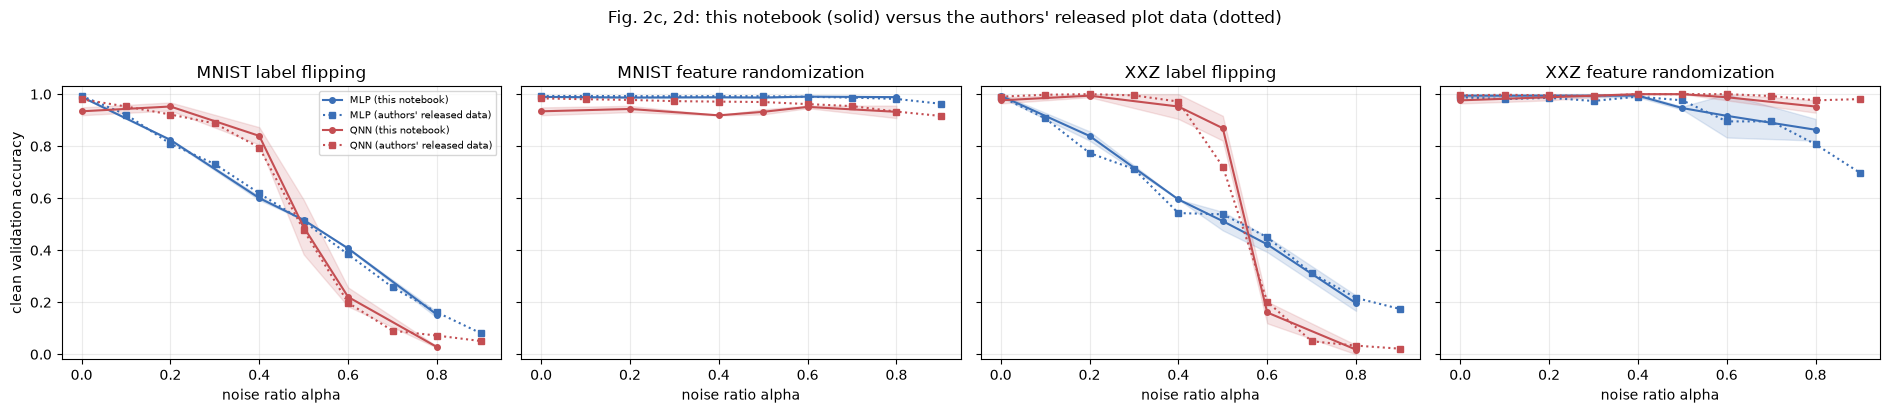

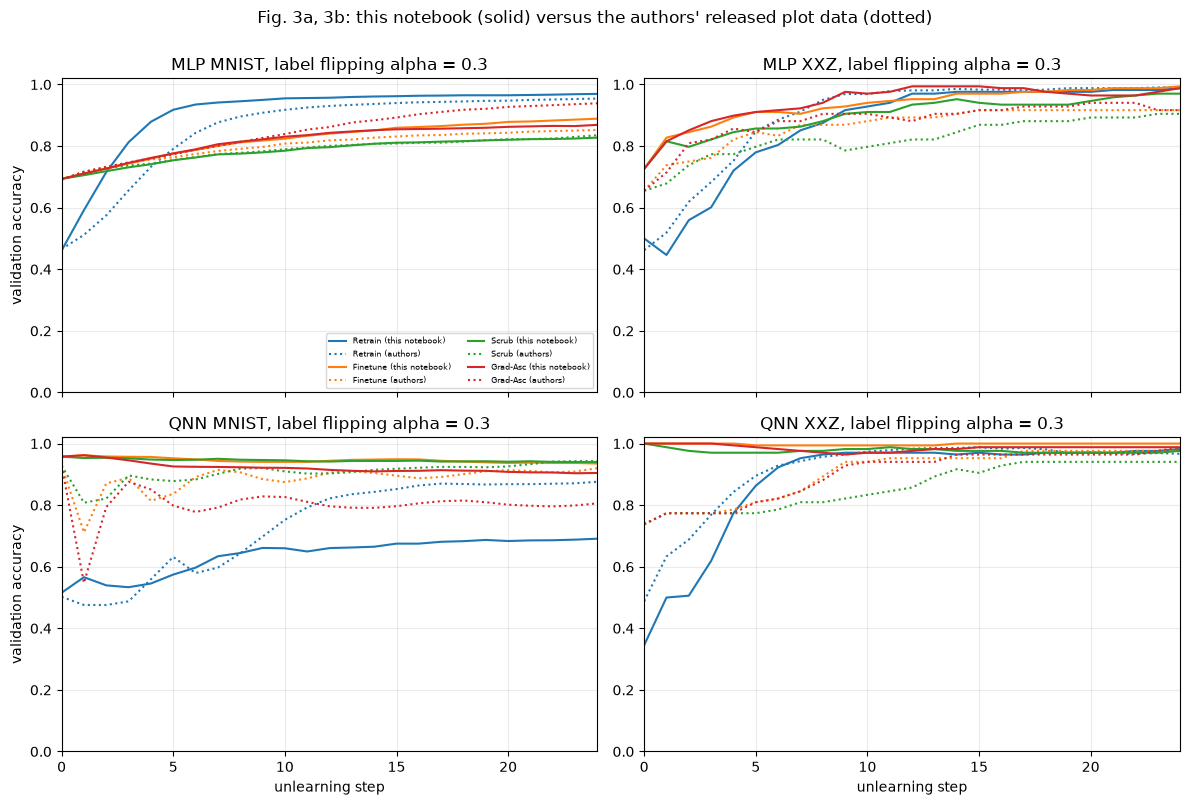

In [27]:
ALPHA_IDX = [int(round(a * 10)) for a in ALPHAS]                    # position of our alphas in the authors' grid 0.0 ... 0.9
if AUTHORS_PLOT:
    fig, axes = plt.subplots(1, 4, figsize=(19, 4), sharey=True)
    for ax, (tk, ci, ttl) in zip(axes, [("mnist", 0, "MNIST label flipping"), ("mnist", 2, "MNIST feature randomization"), ("xxz", 0, "XXZ label flipping"), ("xxz", 2, "XXZ feature randomization")]):
        corr = "flip" if ci == 0 else "rand"
        for kind, off, col in [("mlp", 0, "#3B6FB6"), ("qnn", 1, "#C44E52")]:
            m_, s_ = mean_std(RES1[(tk, kind, corr)][:, :, 1])
            ax.plot(ALPHAS, m_, "-o", color=col, ms=4, label=f"{kind.upper()} (this notebook)"); ax.fill_between(ALPHAS, m_ - s_, m_ + s_, color=col, alpha=0.15)
            a_ = AUTHORS_PLOT[("fig2", tk)]["val_acc"][ci + off]
            ax.plot(np.arange(10) / 10, a_.mean(1), ":s", color=col, ms=4, label=f"{kind.upper()} (authors' released data)")
        ax.set_title(ttl); ax.set_xlabel("noise ratio alpha"); ax.set_ylim(-0.02, 1.03)
    axes[0].set_ylabel("clean validation accuracy"); axes[0].legend(fontsize=7)
    plt.suptitle("Fig. 2c, 2d: this notebook (solid) versus the authors' released plot data (dotted)", y=1.02); plt.tight_layout(); plt.show()

    fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True)
    for ti, tk in enumerate(("mnist", "xxz")):
        for ci, kind in enumerate(("mlp", "qnn")):
            ax = axes[ci, ti]; traj, _ = RES2[(tk, kind)]
            for i, mname in enumerate(METHODS):
                ax.plot(traj["val"][i].mean(0), color=cols[mname], label=f"{mname} (this notebook)")
                ax.plot(AUTHORS_PLOT[("fig3", tk, kind)][i].mean(0), ":", color=cols[mname], label=f"{mname} (authors)")
            ax.set_title(f"{kind.upper()} {'MNIST' if tk == 'mnist' else 'XXZ'}, label flipping alpha = {UNL_ALPHA}"); ax.set_ylim(0, 1.02); ax.set_xlim(0, UNL_EPOCHS - 1)
            if ci == 1: ax.set_xlabel("unlearning step")
            if ti == 0: ax.set_ylabel("validation accuracy")
    axes[0, 0].legend(fontsize=6, ncol=2, loc="lower right")
    plt.suptitle("Fig. 3a, 3b: this notebook (solid) versus the authors' released plot data (dotted)", y=1.0); plt.tight_layout(); plt.show()

In [28]:
def crossing(alphas, vals, level=0.5):
    """First alpha at which the mean validation accuracy falls below `level` (linear interpolation); NaN if it never does."""
    for i in range(1, len(alphas)):
        if vals[i - 1] >= level > vals[i]:
            return alphas[i - 1] + (vals[i - 1] - level) / (vals[i - 1] - vals[i]) * (alphas[i] - alphas[i - 1])
    return np.nan


def ours(tk, kind, corr, a):
    return RES1[(tk, kind, corr)][ALPHAS.index(a), :, 1].mean()


def theirs(tk, kind, corr, a):
    return AUTHORS_PLOT[("fig2", tk)]["val_acc"][(0 if corr == "flip" else 2) + (kind == "qnn")][int(round(a * 10))].mean() if AUTHORS_PLOT else np.nan


# ---- (a) point-by-point comparison with the authors' released curves (Figs. 2c, 2d) ----------------
rows = []
for tk in ("mnist", "xxz"):
    for corr in ("flip", "rand"):
        for kind in ("mlp", "qnn"):
            for a in ALPHAS:
                o, p = ours(tk, kind, corr, a), theirs(tk, kind, corr, a)
                so = RES1[(tk, kind, corr)][ALPHAS.index(a), :, 1].std()
                sp = AUTHORS_PLOT[("fig2", tk)]["val_acc"][(0 if corr == "flip" else 2) + (kind == "qnn")][int(round(a * 10))].std() if AUTHORS_PLOT else np.nan
                rows.append(dict(task=tk, corruption=corr, model=kind.upper(), alpha=a, authors=p, ours=o, diff=o - p, spread=so + sp))
CMP = pd.DataFrame(rows)
if AUTHORS_PLOT:
    CMP["within_2pts"] = CMP["diff"].abs() <= 0.02
    CMP["within_5pts"] = CMP["diff"].abs() <= 0.05
    CMP["within_run_spread"] = CMP["diff"].abs() <= np.maximum(0.02, CMP["spread"])
    print(f"{len(CMP)} (task, corruption, model, alpha) points compared with the authors' released validation accuracies:")
    print(f"  within 2 accuracy points      : {CMP.within_2pts.mean():.0%}")
    print(f"  within 5 accuracy points      : {CMP.within_5pts.mean():.0%}")
    print(f"  within the run-to-run spread  : {CMP.within_run_spread.mean():.0%}   (|difference| <= max(0.02, std_ours + std_authors))")
    print(CMP.groupby(["task", "corruption", "model"])[["within_2pts", "within_5pts", "within_run_spread"]].mean().round(2).to_string())
    print("largest deviations:"); print(CMP.reindex(CMP["diff"].abs().sort_values(ascending=False).index).head(8).round(3).to_string(index=False))

48 (task, corruption, model, alpha) points compared with the authors' released validation accuracies:
  within 2 accuracy points      : 56%
  within 5 accuracy points      : 90%
  within the run-to-run spread  : 85%   (|difference| <= max(0.02, std_ours + std_authors))
                        within_2pts  within_5pts  within_run_spread
task  corruption model                                             
mnist flip       MLP           0.83         1.00               1.00
                 QNN           0.17         1.00               0.67
      rand       MLP           1.00         1.00               1.00
                 QNN           0.33         0.83               0.33
xxz   flip       MLP           0.17         0.67               1.00
                 QNN           0.67         0.83               1.00
      rand       MLP           0.50         0.83               0.83
                 QNN           0.83         1.00               1.00
largest deviations:
 task corruption model  alpha 

In [29]:
CL = []
def claim(cid, source, statement, paper, mine, criterion, ok):
    CL.append(dict(id=cid, source=source, claim=statement, paper_or_authors_data=paper, this_notebook=mine, criterion=criterion, verdict="reproduced" if ok else "not reached"))

fmt3 = lambda x: "n/a" if x is None or (isinstance(x, float) and np.isnan(x)) else f"{x:.3f}"
hi = lambda tk, kind, corr, a: ours(tk, kind, corr, a)
# C1  MNIST label flipping: the MLP degrades immediately, the QNN much less
a_ref = 0.4
gap_o = ours("mnist", "qnn", "flip", a_ref) - ours("mnist", "mlp", "flip", a_ref)
gap_p = theirs("mnist", "qnn", "flip", a_ref) - theirs("mnist", "mlp", "flip", a_ref)
claim("C1", "Fig. 2c", f"MNIST, label flipping: QNN validation accuracy exceeds the MLP's at alpha = {a_ref}", f"gap = {fmt3(gap_p)} (authors' data)", f"gap = {fmt3(gap_o)}", "gap >= +0.05", gap_o >= 0.05)
d_mlp_o = ours("mnist", "mlp", "flip", 0.0) - ours("mnist", "mlp", "flip", 0.2)
d_mlp_p = theirs("mnist", "mlp", "flip", 0.0) - theirs("mnist", "mlp", "flip", 0.2)
claim("C2", "Fig. 2c, text", "MNIST, label flipping: the MLP's validation accuracy degrades from the first noise level on", f"drop(0 -> 0.2) = {fmt3(d_mlp_p)}", f"drop = {fmt3(d_mlp_o)}", "drop >= 0.05", d_mlp_o >= 0.05)
d_q_o = ours("mnist", "qnn", "flip", 0.0) - ours("mnist", "qnn", "flip", 0.2)
claim("C3", "Fig. 2c, text", "MNIST, label flipping: the QNN keeps a plateau for small alpha (at most 4 points lost up to alpha = 0.2)", f"drop(0 -> 0.2) = {fmt3(theirs('mnist','qnn','flip',0.0) - theirs('mnist','qnn','flip',0.2))}", f"drop = {fmt3(d_q_o)}", "drop <= 0.04", d_q_o <= 0.04)
cq_o = crossing(list(ALPHAS), [ours("mnist", "qnn", "flip", a) for a in ALPHAS]); cq_p = crossing(list(np.arange(10) / 10), list(AUTHORS_PLOT[("fig2", "mnist")]["val_acc"][1].mean(1))) if AUTHORS_PLOT else np.nan
claim("C4", "Fig. 2c, text", "MNIST, QNN: the validation accuracy collapses at a critical noise ratio alpha_c ~ 0.5", f"accuracy falls below 0.5 at alpha = {fmt3(cq_p)} (text: 0.5)", f"alpha = {fmt3(cq_o)}", "|alpha_c - 0.5| <= 0.1", abs(cq_o - 0.5) <= 0.1)
cx_o = crossing(list(ALPHAS), [ours("xxz", "qnn", "flip", a) for a in ALPHAS]); cx_p = crossing(list(np.arange(10) / 10), list(AUTHORS_PLOT[("fig2", "xxz")]["val_acc"][1].mean(1))) if AUTHORS_PLOT else np.nan
claim("C5", "Fig. 2d, text", "XXZ, QNN: same critical noise ratio alpha_c ~ 0.5", f"alpha_c = {fmt3(cx_p)}", f"alpha_c = {fmt3(cx_o)}", "|alpha_c - 0.5| <= 0.1", abs(cx_o - 0.5) <= 0.1)
gx_o = ours("xxz", "qnn", "flip", 0.4) - ours("xxz", "mlp", "flip", 0.4); gx_p = theirs("xxz", "qnn", "flip", 0.4) - theirs("xxz", "mlp", "flip", 0.4)
claim("C6", "Fig. 2d", "XXZ, label flipping: the QNN keeps >= 0.9 validation accuracy at alpha = 0.4 while the MLP does not", f"QNN {fmt3(theirs('xxz','qnn','flip',0.4))}, MLP {fmt3(theirs('xxz','mlp','flip',0.4))}", f"QNN {fmt3(ours('xxz','qnn','flip',0.4))}, MLP {fmt3(ours('xxz','mlp','flip',0.4))}", "QNN >= 0.9 and MLP <= 0.8", ours("xxz", "qnn", "flip", 0.4) >= 0.9 and ours("xxz", "mlp", "flip", 0.4) <= 0.8)
claim("C7", "Fig. 2c, text", "MNIST, feature randomization: both models are robust (>= 0.9 validation accuracy up to alpha = 0.6)", f"MLP {fmt3(theirs('mnist','mlp','rand',0.6))}, QNN {fmt3(theirs('mnist','qnn','rand',0.6))} at alpha = 0.6", f"MLP {fmt3(ours('mnist','mlp','rand',0.6))}, QNN {fmt3(ours('mnist','qnn','rand',0.6))}", "both >= 0.9", ours("mnist", "mlp", "rand", 0.6) >= 0.9 and ours("mnist", "qnn", "rand", 0.6) >= 0.9)
claim("C8", "Fig. 2d, text", "XXZ, feature randomization: the MLP degrades for alpha > 0.8 (data-scarce), the QNN does not", f"MLP {fmt3(theirs('xxz','mlp','rand',0.8))}, QNN {fmt3(theirs('xxz','qnn','rand',0.8))} at alpha = 0.8", f"MLP {fmt3(ours('xxz','mlp','rand',0.8))}, QNN {fmt3(ours('xxz','qnn','rand',0.8))}", "QNN - MLP >= 0.05 at alpha = 0.8 and QNN >= 0.9", ours("xxz", "qnn", "rand", 0.8) - ours("xxz", "mlp", "rand", 0.8) >= 0.05 and ours("xxz", "qnn", "rand", 0.8) >= 0.9)

# unlearning claims
def u(tk, kind, method, window):
    traj, _ = RES2[(tk, kind)]; i = METHODS.index(method)
    return traj["val"][i][:, window].mean()
def up(tk, kind, method, window):
    return AUTHORS_PLOT[("fig3", tk, kind)][METHODS.index(method)][:, window].mean() if AUTHORS_PLOT else np.nan
last = slice(UNL_EPOCHS - 5, UNL_EPOCHS)                 # mean over the last 5 recorded steps (less noisy than one step)
first10 = slice(0, 10)
for tk, cid, src in [("mnist", "C9", "Fig. 3a"), ("xxz", "C10", "Fig. 3b")]:
    best_o = max(u(tk, "mlp", mm, last) for mm in METHODS[1:]); best_p = max(up(tk, "mlp", mm, last) for mm in METHODS[1:])
    claim(cid, src, f"{tk.upper()} MLP: Retrain is the upper bound, the cheaper methods lag behind it (last 5 steps)", f"Retrain {fmt3(up(tk,'mlp','Retrain',last))} vs best approximate {fmt3(best_p)}", f"Retrain {fmt3(u(tk,'mlp','Retrain',last))} vs best approximate {fmt3(best_o)}", "Retrain - best approximate >= 0.02", u(tk, "mlp", "Retrain", last) - best_o >= 0.02)
for tk, cid, src in [("mnist", "C11", "Fig. 3a"), ("xxz", "C12", "Fig. 3b")]:
    best_o = max(u(tk, "qnn", mm, first10) for mm in METHODS[1:]); best_p = max(up(tk, "qnn", mm, first10) for mm in METHODS[1:])
    claim(cid, src, f"{tk.upper()} QNN: an approximate method beats Retrain inside the early window (mean of the first 10 steps)", f"Retrain {fmt3(up(tk,'qnn','Retrain',first10))} vs best approximate {fmt3(best_p)}", f"Retrain {fmt3(u(tk,'qnn','Retrain',first10))} vs best approximate {fmt3(best_o)}", "best approximate - Retrain >= 0.02", best_o - u(tk, "qnn", "Retrain", first10) >= 0.02)
# landscape claims
lrr_m = LRR["mlp"][0]; lrr_q = LRR["qnn"][0]
med_m, med_q = lrr_m[lrr_m.alpha > 0].LRR.median(), lrr_q[lrr_q.alpha > 0].LRR.median()
claim("C13", "Fig. 3d", "The MLP's Landscape Roughening Ratio is much larger than 1 (order 10^2)", "order 10^2 (text)", f"median LRR = {med_m:.3g}", "median LRR >= 10", med_m >= 10)
claim("C14", "Fig. 3d", "The QNN's Landscape Roughening Ratio stays near 1 (approximately or smaller than 1)", "~1 or smaller (text)", f"median LRR = {med_q:.3g}", "median LRR <= 2", med_q <= 2)
n_eff_q = QNNEnsemble(1, 10, 6).P
n_mlp = MLPEnsemble(1, 784, (16, 4)).P
claim("C15", "Fig. 3 text", "Parameter counts: 234 trainable angles in the 10-qubit QNN, about 12 600 weights in the 16-4 MLP", "234 and ~12 600", f"{n_eff_q} and {n_mlp}", "within 1 %", n_eff_q == 234 and abs(n_mlp - 12600) / 12600 < 0.01)
VERD = pd.DataFrame(CL)
pd.set_option("display.max_colwidth", 90); pd.set_option("display.width", 250)
print(VERD[["id", "source", "claim", "paper_or_authors_data", "this_notebook", "criterion", "verdict"]].to_string(index=False))
print("\nclaims reproduced:", (VERD.verdict == "reproduced").sum(), "of", len(VERD))

 id        source                                                                                                    claim                                 paper_or_authors_data                           this_notebook                                       criterion     verdict
 C1       Fig. 2c                          MNIST, label flipping: QNN validation accuracy exceeds the MLP's at alpha = 0.4                           gap = 0.176 (authors' data)                             gap = 0.239                                    gap >= +0.05  reproduced
 C2 Fig. 2c, text              MNIST, label flipping: the MLP's validation accuracy degrades from the first noise level on                                drop(0 -> 0.2) = 0.184                            drop = 0.166                                    drop >= 0.05  reproduced
 C3 Fig. 2c, text MNIST, label flipping: the QNN keeps a plateau for small alpha (at most 4 points lost up to alpha = 0.2)                                drop(0 -> 0.2) 

## 8. Reading the paper critically

What this notebook can say, and what it cannot. (The numbers behind each point are in the tables and figures above; they are not repeated here because they change slightly with `FAST_MODE` and with the seeds.)

1. **The headline curves are reproducible, and with good agreement.** Our label-flipping curves follow the authors' released ones closely for both models and both tasks (section 7a gives the share of points inside 2 points, 5 points and the run-to-run spread). The MLP's clean-validation accuracy decreases steadily with the noise ratio; the QNN keeps a higher level up to alpha ~ 0.4 and collapses around 0.5. These are facts about these two specific models trained with these specific optimiser settings, not about "classical versus quantum" in general.
2. **A critical point at alpha = 0.5 is not a discovery.** With balanced classes and symmetric label noise, at alpha = 0.5 the labels carry no information about the class, so *any* learner's validation accuracy has to pass through 50 % there and go below it for alpha > 0.5 (a learner that fits the majority learns the inverted rule). The MLP crosses 0.5 at about the same alpha. What differs is the shape for alpha < 0.5, i.e. how fast accuracy is lost. Calling the QNN's sharper bend a "phase transition" is a metaphor; the data cannot distinguish it from a smooth crossover (5 seeds, a few noise ratios, standard deviations of several tens of points at the transition).
3. **Memorisation versus capacity.** The training-accuracy table of Experiment 1 shows the real difference: the MLP reaches (almost) 100 % accuracy on the *corrupted* training set - it memorises the wrong labels - whereas the QNN's training accuracy stays near 1 - alpha - it cannot memorise. A model that cannot memorise is robust to label noise for the same reason a heavily regularised or early-stopped classical model is. The paper's own statement that the QNN "has a high capacity to memorise" (its Ref. 78) means that this is an inductive bias of *this* circuit with *this* training budget, not an inability. Our extra baselines (section 3, Experiment 1 baseline figure) put a number on it: in the executed run the RBF-SVC on the same normalised pixels loses little accuracy up to alpha = 0.4 on MNIST, i.e. robustness to moderate label noise is not a property that only the QNN has; the linear classifier on the QNN's own features rho behaves very differently on the two tasks (it shows a QNN-like plateau on XXZ but not on MNIST), so the QNN's plateau is not explained by its function class alone either.
4. **The simulated model is small and classically simulable by construction.** Only Z on the last qubit is measured, so the output is a quadratic form <x|O|x> in the input amplitudes where O acts on just the last 6 qubits (MNIST) or 4 qubits (XXZ); gates outside this light cone do not influence the output (the last RZZ layer and most rotations of the last layers have exactly zero gradient, see the circuit section). The 10- and 12-qubit circuits are therefore effectively low-dimensional classical models; "quantum advantage in robustness" is a statement about the inductive bias of this function class, demonstrated here on noiseless simulations only (the paper itself lists hardware noise as open).
5. **Unlearning budgets are not matched across models.** Learning rates, batch sizes and step counts differ between the MLP and the QNN (the MLP uses a whole-retain-set batch with lr 0.001 on MNIST, the QNN batch 256 with lr 0.005). "Finetune beats Retrain within the same window" for the QNN mostly says that a warm start beats a random start when only about a hundred Adam steps are allowed. With a longer window a Retrain QNN would catch up, and the paper itself restricts the claim to "the early training time window". The Scrub of the authors' code is a one-sided KL term (retain-KL weight 0), not the full objective of the paper's Eq. (8). Note also what the unlearning plots show for the QNN: the polluted QNN is hardly polluted - its clean validation accuracy and its accuracy on the clean forget set are already high at step 0 (see the `val_step0` and `forget_acc` columns), because it ignored most of the flipped labels - so there is little to unlearn and every method that does not destroy the model stays close to its starting point, while Retrain starts from a random model. For the MLP on XXZ, in our run the cheap methods catch up with Retrain (claim C10 is 'not reached'), so the 'stubborn memory' of the MLP is data- and budget-dependent.
6. **The Landscape Roughening Ratio is partly a statement about loss saturation.** The MLP's clean training loss goes to (almost) zero, where the Hessian of the cross-entropy vanishes, so any noisy model with a non-zero loss gives a huge ratio. The QNN's output is sigmoid(5 <Z>) with |<Z>| <= 1, so its loss can never reach zero and its Hessian trace never collapses; a ratio near 1 is then expected even if the landscape changes. The ratio is also evaluated on clean held-out data, not on the training loss that the optimiser sees, and the trace (not the spectrum) is estimated by Hutchinson sampling. Exercise 3 asks you to calibrate the MLP's logits.
7. **Data details that matter.** The XXZ validation uses only 84 states and training only 82, with the authors' stored vectors carrying arbitrary global phases (invisible to the amplitude-encoded QNN but a nuisance for the MLP's real/imaginary inputs); the grids differ from the text of the Methods. The authors' optimiser settings were obtained by a grid search that selects on the validation set (their `train_*_model` functions), which makes the "best" configuration slightly optimistic; we use the one configuration their scripts fix. The authors' code uses a ring of RZZ gates whereas the text says a chain (234 angles): we follow the text; the difference may explain why our clean MNIST QNN accuracy is a few points below the authors' released value.
8. **Cannot be checked here.** Everything that lives in the Supplementary Information: the depth / width scans, SVM / logistic regression / CNN / ResNet / random-Fourier-feature results, accuracy on the forget set, the hyper-parameter scans of Scrub and Gradient ascent, the analytic proofs of the Hessian bounds, and the exact optimiser settings behind Figs. 2-3 (we use the authors' scripts). These claims are marked "cannot be checked".

## 9. Exercises

1. **A matched classical baseline.** The QNN cannot memorise noisy labels; can an MLP be made equally robust? Train the MLP of Experiment 1 with early stopping (for example 3-5 epochs), or with a tiny hidden layer (4, 2), or with weight decay, and redraw the label-flipping curve. How much of the QNN's advantage survives?
2. **Fix the phase of the XXZ states.** The stored ground states have random global phases. Apply `gauge_fix` (defined in the exploration section) to the training and validation vectors before they enter the MLP, rerun the XXZ label-flipping curve for the MLP, and compare. Does the MLP's immediate degradation come from the phase nuisance?
3. **A calibrated Landscape Roughening Ratio.** Replace the MLP's output by sigmoid(5 tanh(z / 5)) (bounded logit like the QNN) in `MLPEnsemble.logits`, retrain, and recompute the LRR. Is the "order 10^2" still there? Also try training the MLP for only as many steps as it takes to reach the QNN's clean loss.
4. **Hyper-parameters of the unlearning methods.** The authors scan the forget-term weight of Scrub and Gradient ascent over 0.0 ... 0.9; here it is fixed at 0.2. Rerun Experiment 2 for `W_GA` and `W_SCRUB` in (0.05, 0.2, 0.5, 0.9) and for a common learning rate of 0.005 for both models. Does the QNN keep its advantage when the optimisation budgets are matched?
5. **Ring versus chain (advanced).** The authors' code closes the RZZ chain into a ring (240 angles instead of 234 for MNIST), which widens the light cone to all ten qubits and makes our fast simulator inapplicable. Implement the ring with a full 10-qubit state-vector simulation (for instance PennyLane `lightning.qubit`, one seed, alpha = 0 and 0.3) and check whether the clean-data accuracy moves toward the authors' value.